# 🏠 Advanced Regression Pipeline for House Price Prediction
**Regularization • Cross-Validation • Tree-Based Models • Support Vector Regression**

**Role:** Machine Learning Engineer, Real Estate Analytics Company  
**Dataset:** `Advanced_Regression_HousePrice_Dataset_3800.csv` (3,800 properties, target = `house_price_inr`)

---
### 🎯 Objective
Evaluate advanced supervised-learning regression techniques with a focus on **regularization, model generalization, cross-validation strategies and tree-based regressors**, and learn how to control overfitting, select the optimal model and compare **linear vs non-linear** regressors on real-world data.

### 📝 Problem Statement
The company already uses a basic regression model to predict house prices, but it suffers from **overfitting and unstable predictions** across different datasets. We build a robust regression pipeline that
1. applies **regularization** techniques,
2. uses proper **cross-validation** strategies,
3. compares **linear and non-linear** regression models, and
4. selects the **best-performing model based on validation performance**, which must generalize well on unseen data.

### 🗂️ Notebook Map
| Part | Content |
|---|---|
| A | Conceptual foundation (theory) |
| B | Dataset understanding & preparation |
| C | Regularized linear models (Ridge, Lasso) |
| D | Cross-validation strategies |
| E | Tree-based regression (Decision Tree, Random Forest) |
| F | Support Vector Regression |
| G | Model comparison & evaluation |
| H | Final analysis & reporting (+ saved model for Streamlit) |

## ⚙️ 0. Setup: imports and global settings

In [1]:
import os, io, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, LeaveOneOut,
                                     TimeSeriesSplit, GridSearchCV, cross_val_score,
                                     cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("images", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def inr(x):
    """Format a rupee value in lakh / crore for readable titles."""
    return f"₹{x/1e7:,.2f} Cr" if abs(x) >= 1e7 else f"₹{x/1e5:,.2f} L"

print("scikit-learn version:", sklearn.__version__)
print("pandas version      :", pd.__version__)

scikit-learn version: 1.8.0
pandas version      : 3.0.2


---
# 🧠 Part A: Conceptual Foundation (Theory)

**1. What is Regularization in Machine Learning? Why is it needed?**  
Regularization adds a **penalty on the size of the model coefficients** to the loss function: `Loss = MSE + α · Penalty(w)`. It discourages overly complex models that memorise noise in the training data. It is needed to **reduce overfitting (high variance)**, to handle **multicollinearity** and to improve generalization on unseen data. The strength is controlled by the hyper-parameter **α** (larger α → simpler model).

**2. Difference between Ridge Regression (L2) and Lasso Regression (L1).**  
**Ridge (L2)** penalises the *sum of squared* coefficients (`α Σ w²`); it shrinks coefficients smoothly towards zero but **never makes them exactly zero**, and it works well with correlated features.  
**Lasso (L1)** penalises the *sum of absolute* coefficients (`α Σ |w|`); it can drive some coefficients **exactly to zero**, so it performs **automatic feature selection** and gives sparse, interpretable models.

**3. What is Cross-Validation and why is it important?**  
Cross-validation repeatedly splits the training data into *training* and *validation* parts, trains on one part, scores on the other and **averages the scores**. It gives a **more reliable estimate of generalization** than a single split, is used to **tune hyper-parameters** and **compare models**, and shows how **stable** a model is (via the spread of fold scores).

**4. Cross-validation techniques**
- **K-Fold CV:** data is divided into *k* equal folds; each fold is used once as validation while the other *k-1* folds train the model; the *k* scores are averaged.
- **Stratified K-Fold CV:** like K-Fold, but every fold keeps the **same distribution of the target** as the full data. For regression the continuous target is first **binned** (e.g. into quantile groups) and the bins are stratified.
- **Leave-One-Out CV (LOOCV):** the extreme case *k = n*; each single sample is the validation set once. Almost unbiased but **very expensive** (n model fits) and its estimate can have high variance.
- **Time Series Split:** data is **ordered in time**; the model is always trained on the *past* and validated on the *future* (expanding window). It prevents **look-ahead leakage** and must not be shuffled.

**5. Why are tree-based models less sensitive to feature scaling?**  
A tree chooses splits of the form `feature ≤ threshold` on **one feature at a time**, and only the **ordering** of values matters, not their magnitude. Any monotonic rescaling (standardisation, min-max) leaves the best split unchanged, so scaling has no effect. Distance- or gradient-based models (Ridge, Lasso, SVR) *do* need scaling.

---
# 🧪 Part B: Dataset Understanding & Preparation

In [2]:
DATA_PATH = "data/Advanced_Regression_HousePrice_Dataset_3800.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["sale_date"])
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (3800, 12)


,property_id,sale_date,area_sqft,bedrooms,bathrooms,location_score,property_age,distance_city_km,near_school,near_metro,crime_rate_index,house_price_inr
0,200001,2014-01-01,2181,6,4,8.10,21,3.80,0,0,4.84,35154898
1,200002,2019-12-01,2383,5,4,5.30,28,10.90,1,1,2.89,26710893
2,200003,2016-10-01,1047,3,3,5.90,7,27.50,0,1,4.04,11216242
3,200004,2013-03-01,1753,4,3,7.00,27,12.10,0,0,3.28,21984310
4,200005,2013-07-01,1728,4,4,10.00,32,1.40,0,1,3.84,25080429


In [3]:
buf = io.StringIO()
df.info(buf=buf)
print(buf.getvalue())
print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nDuplicate rows            :", df.duplicated().sum())
print("Duplicate property_id     :", df["property_id"].duplicated().sum())
print("Sale date range           :", df["sale_date"].min().date(), "->", df["sale_date"].max().date())
print("Rows where bathrooms > bedrooms:", int((df["bathrooms"] > df["bedrooms"]).sum()),
      "(plausible, e.g. attached/guest bathrooms, so kept)")

<class 'pandas.DataFrame'>
RangeIndex: 3800 entries, 0 to 3799
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   property_id       3800 non-null   int64         
 1   sale_date         3800 non-null   datetime64[us]
 2   area_sqft         3800 non-null   int64         
 3   bedrooms          3800 non-null   int64         
 4   bathrooms         3800 non-null   int64         
 5   location_score    3800 non-null   float64       
 6   property_age      3800 non-null   int64         
 7   distance_city_km  3800 non-null   float64       
 8   near_school       3800 non-null   int64         
 9   near_metro        3800 non-null   int64         
 10  crime_rate_index  3800 non-null   float64       
 11  house_price_inr   3800 non-null   int64         
dtypes: datetime64[us](1), float64(3), int64(8)
memory usage: 356.4 KB

Missing values per column:
property_id         0
sale_date           0
area_

**Interpretation:** The dataset has **3,800 rows and 12 columns** with **no missing values and no duplicates**, so no imputation or de-duplication is needed. `property_id` is only an identifier (no predictive meaning) and `sale_date` is a monthly date from 2010 to 2023. All other columns are numeric.

In [4]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
property_id,"3,800.00","201,900.50","200,001.00","200,950.75","201,900.50","202,850.25","203,800.00","1,097.11"
sale_date,3800,2016-11-27 23:45:13.263158,2010-01-01 00:00:00,2013-06-01 00:00:00,2016-12-01 00:00:00,2020-05-01 00:00:00,2023-12-01 00:00:00,NaN
area_sqft,"3,800.00","1,716.93",500.00,"1,322.00","1,700.50","2,105.00","3,776.00",583.00
bedrooms,"3,800.00",3.43,1.00,2.00,3.00,4.00,7.00,1.36
bathrooms,"3,800.00",2.92,1.00,2.00,3.00,4.00,6.00,1.13
location_score,"3,800.00",6.50,1.00,5.30,6.50,7.70,10.00,1.77
property_age,"3,800.00",22.54,1.00,14.00,20.00,29.00,80.00,12.33
distance_city_km,"3,800.00",13.09,1.00,8.50,13.00,17.50,38.70,6.54
near_school,"3,800.00",0.55,0.00,0.00,1.00,1.00,1.00,0.50
near_metro,"3,800.00",0.47,0.00,0.00,0.00,1.00,1.00,0.50


**Interpretation:** Property size ranges from 500 to ~3,776 sq.ft. and prices from ~₹15 lakh to ~₹5.9 crore. Features are on very different scales (e.g. `area_sqft` in the thousands vs `near_metro` in 0/1), which is why **scaling is required for Ridge, Lasso and SVR**.

Skewness of target: 0.578


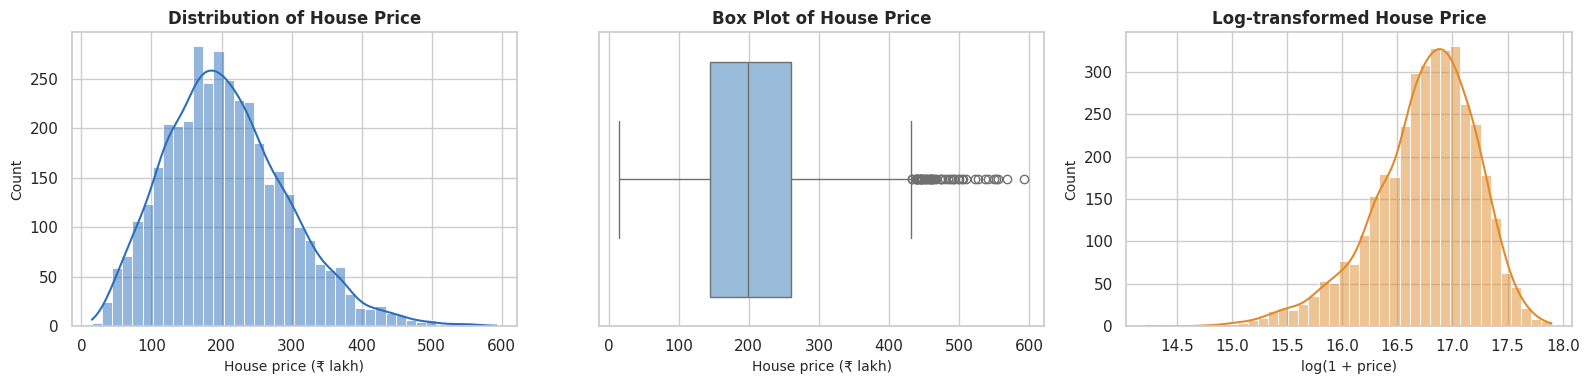

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["house_price_inr"] / 1e5, bins=40, kde=True, ax=axes[0], color="#2a6fbb")
axes[0].set(title="Distribution of House Price", xlabel="House price (₹ lakh)", ylabel="Count")
sns.boxplot(x=df["house_price_inr"] / 1e5, ax=axes[1], color="#8fbce6")
axes[1].set(title="Box Plot of House Price", xlabel="House price (₹ lakh)")
sns.histplot(np.log1p(df["house_price_inr"]), bins=40, kde=True, ax=axes[2], color="#e08a2c")
axes[2].set(title="Log-transformed House Price", xlabel="log(1 + price)")
plt.tight_layout(); plt.savefig("images/01_target_distribution.png", bbox_inches="tight")
print("Skewness of target:", round(df["house_price_inr"].skew(), 3))

**Interpretation:** The target is **mildly right-skewed** (skewness ≈ 0.58) with a few expensive properties. The skew is moderate, so we keep the target on its original rupee scale, which also keeps all error metrics directly interpretable in ₹.

,corr_with_price
area_sqft,0.85
bedrooms,0.73
bathrooms,0.61
location_score,0.43
sale_year,0.03
near_school,-0.01
near_metro,-0.02
crime_rate_index,-0.05
property_age,-0.08
distance_city_km,-0.28


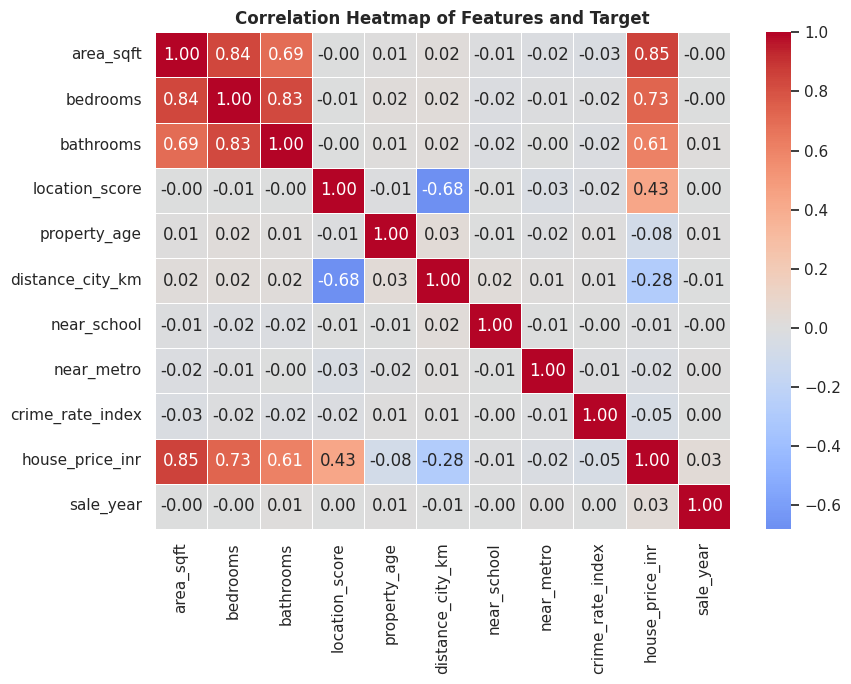

In [6]:
df["sale_year"] = df["sale_date"].dt.year          # numeric time feature
corr = df.drop(columns=["property_id", "sale_date"]).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Features and Target")
plt.tight_layout(); plt.savefig("images/02_correlation_heatmap.png", bbox_inches="tight")
corr["house_price_inr"].drop("house_price_inr").sort_values(ascending=False).to_frame("corr_with_price")

**Interpretation:** `area_sqft` (r ≈ 0.85) is by far the strongest driver of price, followed by `bedrooms` (0.73), `bathrooms` (0.61) and `location_score` (0.43). `distance_city_km` is negatively related (-0.28). `bedrooms`, `bathrooms` and `area_sqft` are correlated with each other (**multicollinearity**), which is exactly the situation where regularization helps.

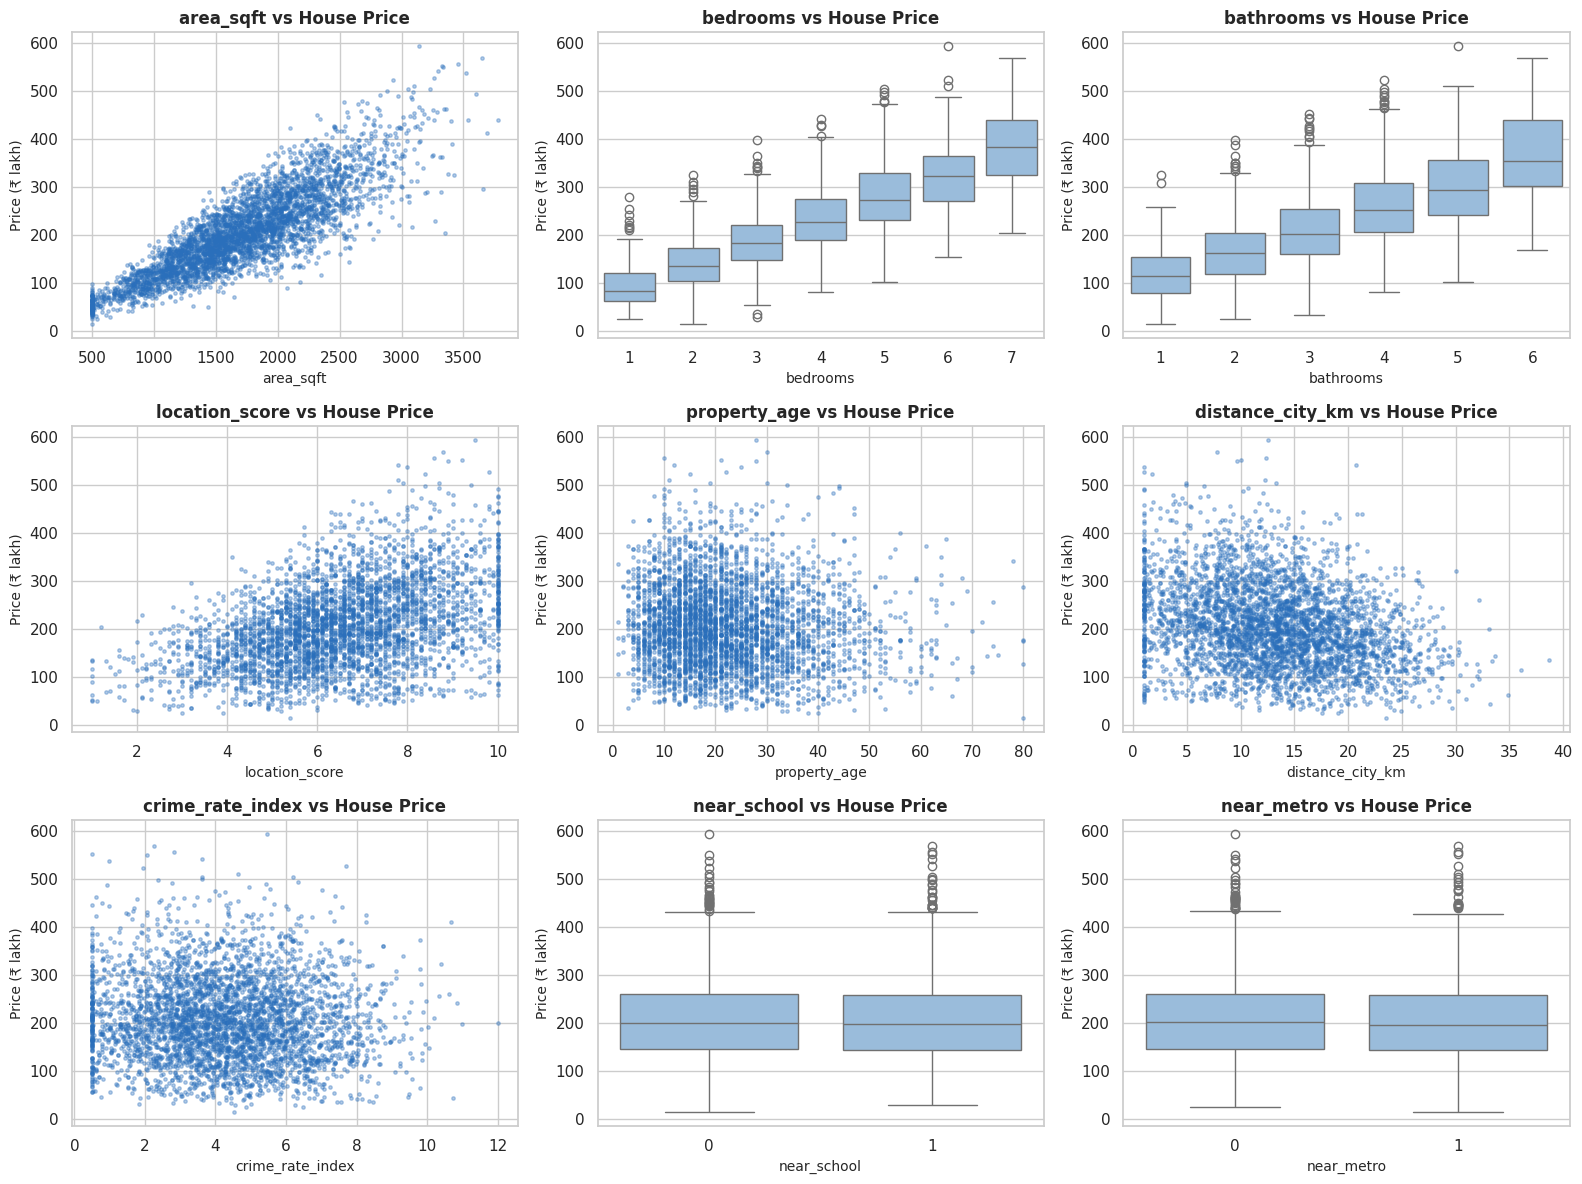

In [7]:
num_feats = ["area_sqft", "bedrooms", "bathrooms", "location_score", "property_age",
             "distance_city_km", "crime_rate_index", "near_school", "near_metro"]
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.ravel(), num_feats):
    if df[col].nunique() <= 8:
        sns.boxplot(x=df[col], y=df["house_price_inr"] / 1e5, ax=ax, color="#8fbce6")
    else:
        ax.scatter(df[col], df["house_price_inr"] / 1e5, s=6, alpha=0.35, color="#2a6fbb")
    ax.set(title=f"{col} vs House Price", xlabel=col, ylabel="Price (₹ lakh)")
plt.tight_layout(); plt.savefig("images/03_feature_vs_price.png", bbox_inches="tight")

**Interpretation:** Price rises almost linearly with area, bedrooms, bathrooms and location score, and falls with distance from the city. `near_school`, `near_metro`, `crime_rate_index` and `property_age` show only weak individual relationships. The cloud widens for larger houses (price variance grows with size), a mild non-linearity that tree models and SVR can capture.

In [8]:
# Outlier check with the IQR rule (we only inspect; we do not delete data)
rows = []
for col in ["area_sqft", "bedrooms", "bathrooms", "location_score", "property_age",
            "distance_city_km", "crime_rate_index", "house_price_inr"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum())
    rows.append({"feature": col, "outliers (IQR rule)": n_out, "% of rows": round(100 * n_out / len(df), 2)})
pd.DataFrame(rows)

,feature,outliers (IQR rule),% of rows
0,area_sqft,22,0.58
1,bedrooms,0,0.00
2,bathrooms,0,0.00
3,location_score,20,0.53
4,property_age,104,2.74
5,distance_city_km,13,0.34
6,crime_rate_index,13,0.34
7,house_price_inr,52,1.37


**Interpretation:** Only a small share of rows are flagged and the values are realistic (large villas, very old buildings, expensive properties), not data-entry errors. We therefore **keep them**: removing genuine expensive properties would make the model blind to the high-price segment. Tree models are naturally robust to them, and regularization limits their influence on linear models.

### Task 6: Identify features and target variable

In [9]:
TARGET = "house_price_inr"
FEATURES = ["area_sqft", "bedrooms", "bathrooms", "location_score", "property_age",
            "distance_city_km", "near_school", "near_metro", "crime_rate_index", "sale_year"]
# property_id is only an identifier -> dropped; sale_date is kept ONLY for time-series CV (Part D)
X = df[FEATURES].copy()
y = df[TARGET].copy()
print("Target   :", TARGET)
print("Features :", FEATURES)
print("X shape  :", X.shape, "| y shape:", y.shape)

Target   : house_price_inr
Features : ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'property_age', 'distance_city_km', 'near_school', 'near_metro', 'crime_rate_index', 'sale_year']
X shape  : (3800, 10) | y shape: (3800,)


**Interpretation:** The target is `house_price_inr`. The 10 predictors cover **size & structure** (`area_sqft`, `bedrooms`, `bathrooms`), **location indicators** (`location_score`, `distance_city_km`, `near_school`, `near_metro`, `crime_rate_index`) and **age/time** (`property_age`, `sale_year` derived from `sale_date`). `property_id` is dropped because an ID carries no information about price.

### Task 7: Train–test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows ({X_train.shape[0]/len(X):.0%})   Test: {X_test.shape[0]} rows ({X_test.shape[0]/len(X):.0%})")
print(f"Mean price  - train: {inr(y_train.mean())}   test: {inr(y_test.mean())}")
print(f"Std of price - train: {inr(y_train.std())}   test: {inr(y_test.std())}")

Train: 3040 rows (80%)   Test: 760 rows (20%)
Mean price  - train: ₹2.08 Cr   test: ₹2.05 Cr
Std of price - train: ₹86.39 L   test: ₹89.80 L


**Interpretation:** We use an **80/20 split** with a fixed `random_state`. The 20% **test set is locked away** and used only once for the final comparison; all tuning is done on the training data with cross-validation. Train and test price statistics are very similar, so the split is representative.

### Task 8: Basic preprocessing (scaling where required)

In [11]:
scaler_demo = StandardScaler().fit(X_train)            # fit on TRAIN only (no data leakage)
X_train_scaled = pd.DataFrame(scaler_demo.transform(X_train), columns=FEATURES, index=X_train.index)
summary = pd.DataFrame({"mean (before)": X_train.mean(), "std (before)": X_train.std(),
                        "mean (after)": X_train_scaled.mean(), "std (after)": X_train_scaled.std()})
summary

,mean (before),std (before),mean (after),std (after)
area_sqft,"1,721.15",584.36,-0.00,1.00
bedrooms,3.44,1.36,-0.00,1.00
bathrooms,2.92,1.14,0.00,1.00
location_score,6.51,1.74,0.00,1.00
property_age,22.55,12.34,-0.00,1.00
distance_city_km,13.10,6.55,-0.00,1.00
near_school,0.55,0.50,-0.00,1.00
near_metro,0.47,0.50,0.00,1.00
crime_rate_index,4.24,2.05,-0.00,1.00
sale_year,"2,016.45",4.02,-0.00,1.00


**Interpretation:** `StandardScaler` transforms every feature to **mean 0 and standard deviation 1**. Scaling is **required** for Ridge, Lasso (the penalty treats all coefficients equally, so features must be on the same scale) and SVR (kernels use distances). It is **not required** for Decision Tree / Random Forest.  
To avoid **data leakage**, the scaler is always placed **inside a `Pipeline`**, so inside every cross-validation fold it is fitted only on that fold's training part.

---
# 📉 Part C: Regularized Linear Models

In [12]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # main CV used for tuning
SCORING = "neg_root_mean_squared_error"
results = []                                                         # collects all model metrics

def evaluate(name, group, model):
    """Fit-free evaluation of an already fitted model: train/test metrics + 5-fold CV on the training set."""
    p_tr, p_te = model.predict(X_train), model.predict(X_test)
    cv = -cross_val_score(clone(model), X_train, y_train, cv=cv5, scoring=SCORING)
    row = {"Model": name, "Group": group,
           "Train_MSE": mean_squared_error(y_train, p_tr), "Test_MSE": mean_squared_error(y_test, p_te),
           "Train_MAE": mean_absolute_error(y_train, p_tr), "Test_MAE": mean_absolute_error(y_test, p_te),
           "Train_RMSE": rmse(y_train, p_tr), "Test_RMSE": rmse(y_test, p_te),
           "Train_R2": r2_score(y_train, p_tr), "Test_R2": r2_score(y_test, p_te),
           "CV_RMSE": cv.mean(), "CV_RMSE_std": cv.std()}
    results.append(row)
    return row

def make_pipe(est):
    return Pipeline([("scaler", StandardScaler()), ("model", est)])

# Baseline: ordinary least squares (no regularization)
lin = make_pipe(LinearRegression()).fit(X_train, y_train)
_ = evaluate("Linear Regression (OLS)", "Linear", lin)
print("Baseline OLS fitted.")

Baseline OLS fitted.


We first fit an **un-regularized OLS baseline** (the "basic regression model" the company already uses). Ridge and Lasso will be compared against it.

### Task 9–11: Implement Ridge (L2) & Lasso (L1) and tune α with cross-validation

In [13]:
ridge_gs = GridSearchCV(make_pipe(Ridge(random_state=RANDOM_STATE)),
                        {"model__alpha": np.logspace(-3, 4, 40)},
                        cv=cv5, scoring=SCORING, return_train_score=True, n_jobs=-1).fit(X_train, y_train)

# Lasso's alpha depends on the scale of y (rupees), so its grid is much larger than Ridge's grid
lasso_gs = GridSearchCV(make_pipe(Lasso(max_iter=100000, random_state=RANDOM_STATE)),
                        {"model__alpha": np.logspace(2, 7, 40)},
                        cv=cv5, scoring=SCORING, return_train_score=True, n_jobs=-1).fit(X_train, y_train)

print(f"Best Ridge alpha : {ridge_gs.best_params_['model__alpha']:.4g}   (CV RMSE = {-ridge_gs.best_score_:,.0f})")
print(f"Best Lasso alpha : {lasso_gs.best_params_['model__alpha']:.4g}   (CV RMSE = {-lasso_gs.best_score_:,.0f})")
ridge, lasso = ridge_gs.best_estimator_, lasso_gs.best_estimator_
_ = evaluate("Ridge (L2)", "Linear", ridge)
_ = evaluate("Lasso (L1)", "Linear", lasso)
pd.DataFrame(results)[["Model", "Train_RMSE", "CV_RMSE", "Test_RMSE", "Test_R2"]]

Best Ridge alpha : 1.701   (CV RMSE = 2,495,117)
Best Lasso alpha : 1.125e+04   (CV RMSE = 2,494,929)


,Model,Train_RMSE,CV_RMSE,Test_RMSE,Test_R2
0,Linear Regression (OLS),"2,482,455.56","2,495,140.89","2,539,147.88",0.92
1,Ridge (L2),"2,482,466.52","2,495,117.33","2,539,565.84",0.92
2,Lasso (L1),"2,482,642.15","2,494,928.82","2,541,895.62",0.92


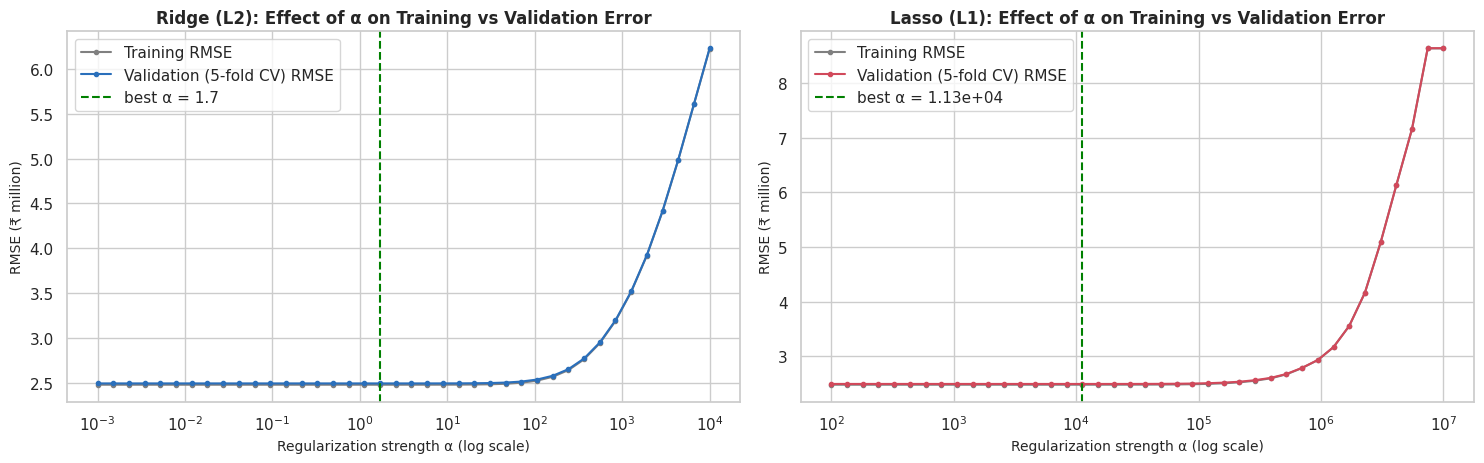

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, gs, name, color in [(axes[0], ridge_gs, "Ridge (L2)", "#2a6fbb"), (axes[1], lasso_gs, "Lasso (L1)", "#d1495b")]:
    r = pd.DataFrame(gs.cv_results_)
    a = r["param_model__alpha"].astype(float)
    ax.plot(a, -r["mean_train_score"] / 1e6, "o-", ms=3, color="gray", label="Training RMSE")
    ax.plot(a, -r["mean_test_score"] / 1e6, "o-", ms=3, color=color, label="Validation (5-fold CV) RMSE")
    best = gs.best_params_["model__alpha"]
    ax.axvline(best, ls="--", color="green", label=f"best α = {best:,.3g}")
    ax.set(xscale="log", xlabel="Regularization strength α (log scale)", ylabel="RMSE (₹ million)",
           title=f"{name}: Effect of α on Training vs Validation Error")
    ax.legend()
plt.tight_layout(); plt.savefig("images/04_alpha_tuning_ridge_lasso.png", bbox_inches="tight")

**Interpretation:** For small α the validation error is flat and close to the training error, so the penalty has almost no effect. As α grows beyond the optimum both errors rise (the model is **over-regularized → underfits**). The green line is the α picked by 5-fold cross-validation. Because the features are few and the signal is strong, the optimum α is small, i.e. this dataset only needs a **light** penalty.

### Task 12: Compare Ridge and Lasso: training error, validation error, coefficient behaviour

In [15]:
def coefs(pipe): return pipe.named_steps["model"].coef_
coef_df = pd.DataFrame({"OLS": coefs(lin), "Ridge": coefs(ridge), "Lasso": coefs(lasso)}, index=FEATURES)

# "1-standard-error rule": strongest Lasso penalty whose CV error is within 1 SE of the best -> shows sparsity
r = pd.DataFrame(lasso_gs.cv_results_)
i_best = r["mean_test_score"].idxmax()
se = r.loc[i_best, "std_test_score"] / np.sqrt(5)
ok = r[r["mean_test_score"] >= r.loc[i_best, "mean_test_score"] - se]
alpha_1se = float(ok["param_model__alpha"].astype(float).max())
lasso_1se = make_pipe(Lasso(alpha=alpha_1se, max_iter=100000)).fit(X_train, y_train)
coef_df["Lasso (1-SE α)"] = coefs(lasso_1se)
print(f"Lasso alpha chosen by 1-SE rule: {alpha_1se:,.0f}")
display((coef_df / 1e5).round(2).rename_axis("feature (coef in ₹ lakh per 1 SD)"))

tab = pd.DataFrame({
    "Training RMSE": [rmse(y_train, m.predict(X_train)) for m in (lin, ridge, lasso, lasso_1se)],
    "Validation RMSE (CV)": [-cross_val_score(clone(m), X_train, y_train, cv=cv5, scoring=SCORING).mean() for m in (lin, ridge, lasso, lasso_1se)],
    "Σ|coef|": [np.abs(coefs(m)).sum() for m in (lin, ridge, lasso, lasso_1se)],
    "Σ coef²": [(coefs(m) ** 2).sum() for m in (lin, ridge, lasso, lasso_1se)],
    "# zero coefs": [int((np.abs(coefs(m)) < 1e-6).sum()) for m in (lin, ridge, lasso, lasso_1se)],
}, index=["OLS", "Ridge", "Lasso (best α)", "Lasso (1-SE α)"])
tab

Lasso alpha chosen by 1-SE rule: 160,372


,OLS,Ridge,Lasso,Lasso (1-SE α)
feature (coef in ₹ lakh per 1 SD),,,,
area_sqft,69.56,69.43,69.48,68.69
bedrooms,2.90,3.00,2.90,2.64
bathrooms,2.72,2.72,2.67,1.97
location_score,36.81,36.78,36.75,35.42
property_age,-6.50,-6.50,-6.40,-4.97
distance_city_km,-0.27,-0.29,-0.20,-0.00
near_school,0.15,0.16,0.04,0.00
near_metro,0.53,0.52,0.42,0.00
crime_rate_index,-1.41,-1.41,-1.30,-0.00


,Training RMSE,Validation RMSE (CV),Σ|coef|,Σ coef²,# zero coefs
OLS,"2,482,455.56","2,495,140.89","12,386,196.39","62,633,958,181,730.82",0
Ridge,"2,482,466.52","2,495,117.33","12,382,203.00","62,439,180,207,563.27",0
Lasso (best α),"2,482,642.15","2,494,928.82","12,304,163.82","62,448,261,650,956.88",0
Lasso (1-SE α),"2,508,508.51","2,518,748.45","11,509,928.27","60,104,559,943,686.53",4


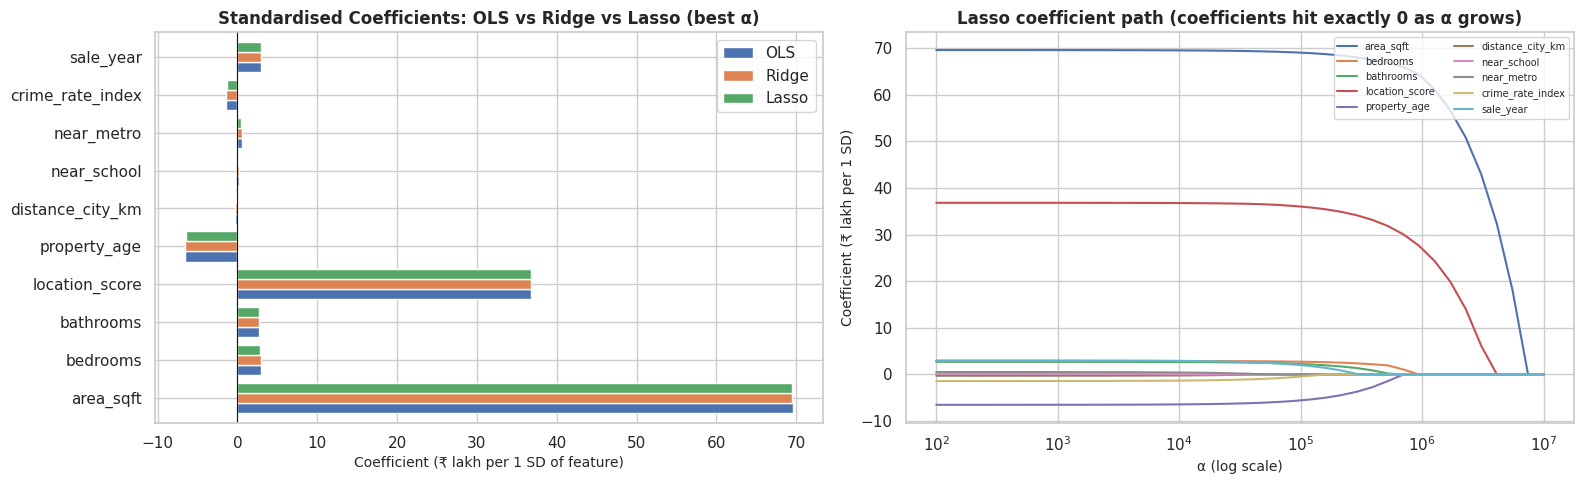

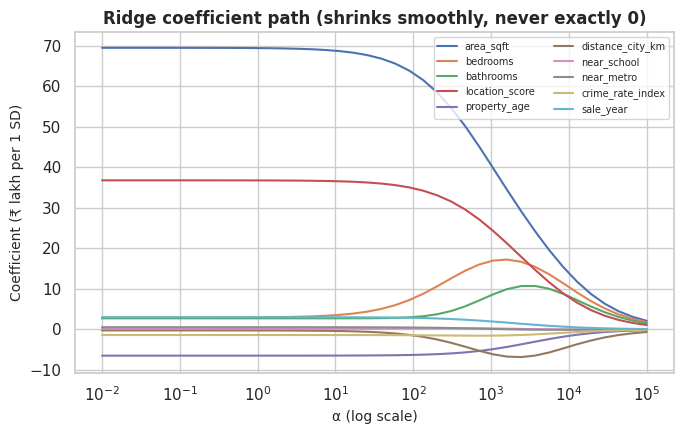

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
(coef_df[["OLS", "Ridge", "Lasso"]] / 1e5).plot(kind="barh", ax=axes[0], width=0.8)
axes[0].set(title="Standardised Coefficients: OLS vs Ridge vs Lasso (best α)", xlabel="Coefficient (₹ lakh per 1 SD of feature)")
axes[0].axvline(0, color="k", lw=0.8)

Xs = StandardScaler().fit_transform(X_train)
alphas_r, alphas_l = np.logspace(-2, 5, 40), np.logspace(2, 7, 40)
path_r = np.array([Ridge(alpha=a).fit(Xs, y_train).coef_ for a in alphas_r]) / 1e5
path_l = np.array([Lasso(alpha=a, max_iter=100000).fit(Xs, y_train).coef_ for a in alphas_l]) / 1e5
for k, f in enumerate(FEATURES):
    axes[1].plot(alphas_l, path_l[:, k], label=f)
axes[1].set(xscale="log", title="Lasso coefficient path (coefficients hit exactly 0 as α grows)",
            xlabel="α (log scale)", ylabel="Coefficient (₹ lakh per 1 SD)")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig("images/05_coefficients_ridge_lasso.png", bbox_inches="tight")

plt.figure(figsize=(7, 4.5))
for k, f in enumerate(FEATURES):
    plt.plot(alphas_r, path_r[:, k], label=f)
plt.xscale("log"); plt.xlabel("α (log scale)"); plt.ylabel("Coefficient (₹ lakh per 1 SD)")
plt.title("Ridge coefficient path (shrinks smoothly, never exactly 0)"); plt.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig("images/06_ridge_path.png", bbox_inches="tight")

**Interpretation (Ridge vs Lasso):**  
- **Training error:** OLS, Ridge and Lasso have practically the same training RMSE (≈ ₹24.8 lakh); the penalty only makes training error a hair higher, as expected for any regularized model.  
- **Validation error:** the three are also practically identical (CV RMSE ≈ ₹24.95 lakh). Regularization does **not** give a big accuracy jump here because plain OLS is *not* overfitted (10 features, 3,040 rows, train R² ≈ test R² ≈ 0.92). Its benefit is **stability/safety**: coefficients are slightly shrunk and the model is protected against multicollinearity and new datasets.  
- **Coefficient behaviour:** Ridge **shrinks all coefficients smoothly and none becomes exactly zero**. Lasso at the CV-best α keeps all features, but with the stronger **1-SE α** it sets **4 coefficients exactly to zero** (`distance_city_km`, `near_school`, `near_metro`, `crime_rate_index`) at a cost of only ≈ ₹0.24 lakh in CV RMSE, which shows these four add almost nothing once `location_score` and size are known. `area_sqft` dominates in every model (≈ ₹69 lakh per 1 SD), followed by `location_score` (≈ ₹37 lakh per SD).  
- **Why Lasso zeroes `distance_city_km`:** distance is correlated with `location_score`, so the L1 penalty keeps one and drops the other, typical Lasso behaviour with correlated features.

---
# 🔁 Part D: Cross-Validation Strategies
We evaluate the **tuned Ridge** model (fast enough for LOOCV) on the **training set** with four strategies and compare how the metrics change.

In [17]:
ridge_cv_model = clone(ridge)            # tuned Ridge pipeline (scaler + Ridge(best alpha))

# Stratified K-Fold for a continuous target -> bin the target into 10 quantile groups
y_bins = pd.qcut(y_train, q=10, labels=False)
print("Samples per target bin:", np.bincount(y_bins).tolist())

# Time-series CV needs data ordered by time -> sort the TRAINING rows by sale_date
order = df.loc[X_train.index, "sale_date"].sort_values(kind="mergesort").index
X_ts, y_ts = X_train.loc[order], y_train.loc[order]

def run_splits(splitter, Xd, yd, strat=None, label=""):
    t0, folds = time.time(), []
    for tr, va in splitter.split(Xd, strat if strat is not None else yd):
        m = clone(ridge_cv_model).fit(Xd.iloc[tr], yd.iloc[tr])
        p = m.predict(Xd.iloc[va])
        folds.append({"RMSE": rmse(yd.iloc[va], p), "MAE": mean_absolute_error(yd.iloc[va], p), "R2": r2_score(yd.iloc[va], p)})
    f = pd.DataFrame(folds)
    return {"Strategy": label, "Model fits": len(f), "RMSE mean": f["RMSE"].mean(), "RMSE std": f["RMSE"].std(),
            "MAE mean": f["MAE"].mean(), "R2 mean": f["R2"].mean(), "R2 std": f["R2"].std(),
            "Time (s)": time.time() - t0}, f["RMSE"].values

cv_rows, fold_rmse = [], {}
for label, splitter, Xd, yd, strat in [
        ("K-Fold (k=5)", KFold(5, shuffle=True, random_state=RANDOM_STATE), X_train, y_train, None),
        ("Stratified K-Fold (k=5, binned y)", StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), X_train, y_train, y_bins),
        ("Time Series Split (5 splits)", TimeSeriesSplit(n_splits=5), X_ts, y_ts, None)]:
    row, folds = run_splits(splitter, Xd, yd, strat, label)
    cv_rows.append(row); fold_rmse[label] = folds

# Leave-One-Out: one model per sample -> use pooled predictions (a single fold has 1 sample)
t0 = time.time()
p_loo = cross_val_predict(clone(ridge_cv_model), X_train, y_train, cv=LeaveOneOut(), n_jobs=-1)
cv_rows.append({"Strategy": "Leave-One-Out (LOOCV)", "Model fits": len(X_train), "RMSE mean": rmse(y_train, p_loo),
                "RMSE std": np.nan, "MAE mean": mean_absolute_error(y_train, p_loo), "R2 mean": r2_score(y_train, p_loo),
                "R2 std": np.nan, "Time (s)": time.time() - t0})
cv_table = pd.DataFrame(cv_rows).set_index("Strategy")
cv_table

Samples per target bin: [304, 304, 304, 304, 304, 304, 304, 304, 304, 304]


,Model fits,RMSE mean,RMSE std,MAE mean,R2 mean,R2 std,Time (s)
Strategy,,,,,,,
K-Fold (k=5),5,"2,495,117.33","99,392.03","1,906,682.46",0.92,0.01,0.03
"Stratified K-Fold (k=5, binned y)",5,"2,492,475.16","79,170.50","1,905,407.80",0.92,0.00,0.03
Time Series Split (5 splits),5,"2,490,251.67","118,327.21","1,903,626.43",0.92,0.01,0.03
Leave-One-Out (LOOCV),3040,"2,492,292.29",NaN,"1,903,908.52",0.92,NaN,15.71


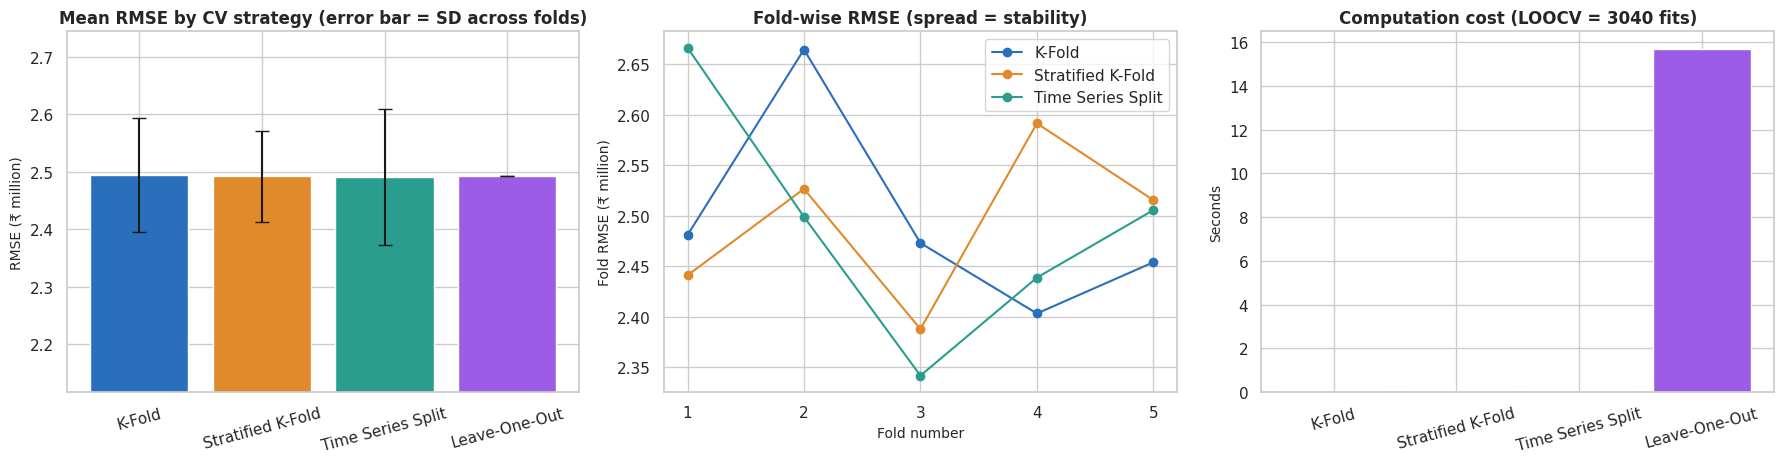

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
names = cv_table.index.tolist()
cols = ["#2a6fbb", "#e08a2c", "#2a9d8f", "#9b5de5"]
axes[0].bar(range(4), cv_table["RMSE mean"] / 1e6, yerr=cv_table["RMSE std"].fillna(0) / 1e6, color=cols, capsize=5)
axes[0].set_xticks(range(4)); axes[0].set_xticklabels([n.split(" (")[0] for n in names], rotation=15)
axes[0].set(ylabel="RMSE (₹ million)", title="Mean RMSE by CV strategy (error bar = SD across folds)")
axes[0].set_ylim(cv_table["RMSE mean"].min() / 1e6 * 0.85, cv_table["RMSE mean"].max() / 1e6 * 1.1)
for lab, c in zip(list(fold_rmse), cols):
    axes[1].plot(range(1, 6), fold_rmse[lab] / 1e6, "o-", color=c, label=lab.split(" (")[0])
axes[1].set(xlabel="Fold number", ylabel="Fold RMSE (₹ million)", title="Fold-wise RMSE (spread = stability)", xticks=range(1, 6))
axes[1].legend()
axes[2].bar(range(4), cv_table["Time (s)"], color=cols)
axes[2].set_xticks(range(4)); axes[2].set_xticklabels([n.split(" (")[0] for n in names], rotation=15)
axes[2].set(ylabel="Seconds", title=f"Computation cost (LOOCV = {len(X_train)} fits)")
plt.tight_layout(); plt.savefig("images/07_cv_strategies.png", bbox_inches="tight")

### Task 14: How do the metrics vary across CV strategies?
- **K-Fold, Stratified K-Fold and LOOCV give nearly the same RMSE/R²**, so the Ridge model's performance estimate is **consistent** and the model is stable. Stratification mainly makes fold-to-fold scores slightly less variable, because each fold contains the same mix of cheap and expensive houses.
- **LOOCV** is almost unbiased but needs **one fit per sample** (3,040 fits), so it is by far the most expensive and gives no per-fold spread.
- **Time Series Split** gives a different (and typically noisier) picture: early splits train on very little history, and every score is for the *future* relative to the training window. It is the right strategy only if prices are time-dependent; here the sale year has almost no trend, so the result stays similar, but its fold scores are the most variable.
- **Conclusion:** use **K-Fold / Stratified K-Fold** for model selection on this data (cheap and reliable); keep Time Series Split for any deployment where we predict future sales; avoid LOOCV except for small datasets.

---
# 🌳 Part E: Tree-Based Regression Models

### Task 15: Decision Tree Regression: an unrestricted tree (baseline)

In [19]:
dt_full = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(X_train, y_train)
print("Unrestricted tree  ->  depth:", dt_full.get_depth(), "| leaves:", dt_full.get_n_leaves())
print(f"Train R² = {dt_full.score(X_train, y_train):.4f}    Test R² = {dt_full.score(X_test, y_test):.4f}")
_ = evaluate("Decision Tree (unrestricted)", "Tree-based", dt_full)

Unrestricted tree  ->  depth: 21 | leaves: 3040
Train R² = 1.0000    Test R² = 0.8740


**Interpretation:** An unrestricted tree grows until every training house sits in its own leaf, giving **R² = 1.00 on training data** but a clearly **lower R² on the test data**. This is the classic **overfitting (high variance)** problem, so we must control complexity.

### Task 16: Control tree complexity (max_depth, min_samples_split, min_samples_leaf)

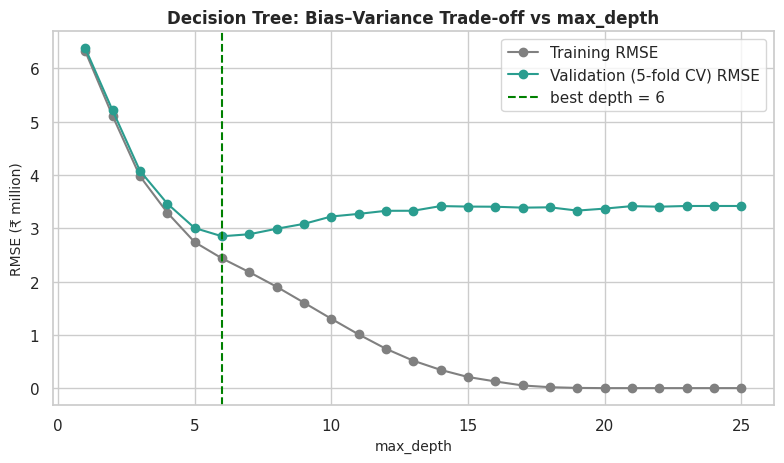

In [20]:
depths = list(range(1, 26))
tr_err, cv_err = [], []
for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    tr_err.append(rmse(y_train, m.predict(X_train)))
    cv_err.append(-cross_val_score(m, X_train, y_train, cv=cv5, scoring=SCORING).mean())
plt.figure(figsize=(8, 4.8))
plt.plot(depths, np.array(tr_err) / 1e6, "o-", color="gray", label="Training RMSE")
plt.plot(depths, np.array(cv_err) / 1e6, "o-", color="#2a9d8f", label="Validation (5-fold CV) RMSE")
plt.axvline(depths[int(np.argmin(cv_err))], ls="--", color="green", label=f"best depth = {depths[int(np.argmin(cv_err))]}")
plt.xlabel("max_depth"); plt.ylabel("RMSE (₹ million)")
plt.title("Decision Tree: Bias–Variance Trade-off vs max_depth"); plt.legend()
plt.tight_layout(); plt.savefig("images/08_tree_depth_curve.png", bbox_inches="tight")

**Interpretation:** Shallow trees (depth 1–3) **underfit**: both errors are high. As depth increases the training error keeps falling toward zero, but the validation error stops improving and then rises again: that gap is **overfitting**. The best depth is where the validation error is lowest.

In [21]:
dt_gs = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE),
                     {"max_depth": [3, 4, 5, 6, 7, 8, 10, 12, None],
                      "min_samples_split": [2, 10, 30],
                      "min_samples_leaf": [1, 5, 15, 30]},
                     cv=cv5, scoring=SCORING, n_jobs=-1).fit(X_train, y_train)
dt = dt_gs.best_estimator_
print("Best Decision Tree parameters:", dt_gs.best_params_)
print(f"CV RMSE = {-dt_gs.best_score_:,.0f}   |  depth = {dt.get_depth()}, leaves = {dt.get_n_leaves()}")
_ = evaluate("Decision Tree (tuned)", "Tree-based", dt)

Best Decision Tree parameters: {'max_depth': 12, 'min_samples_leaf': 15, 'min_samples_split': 2}
CV RMSE = 2,700,810   |  depth = 10, leaves = 155


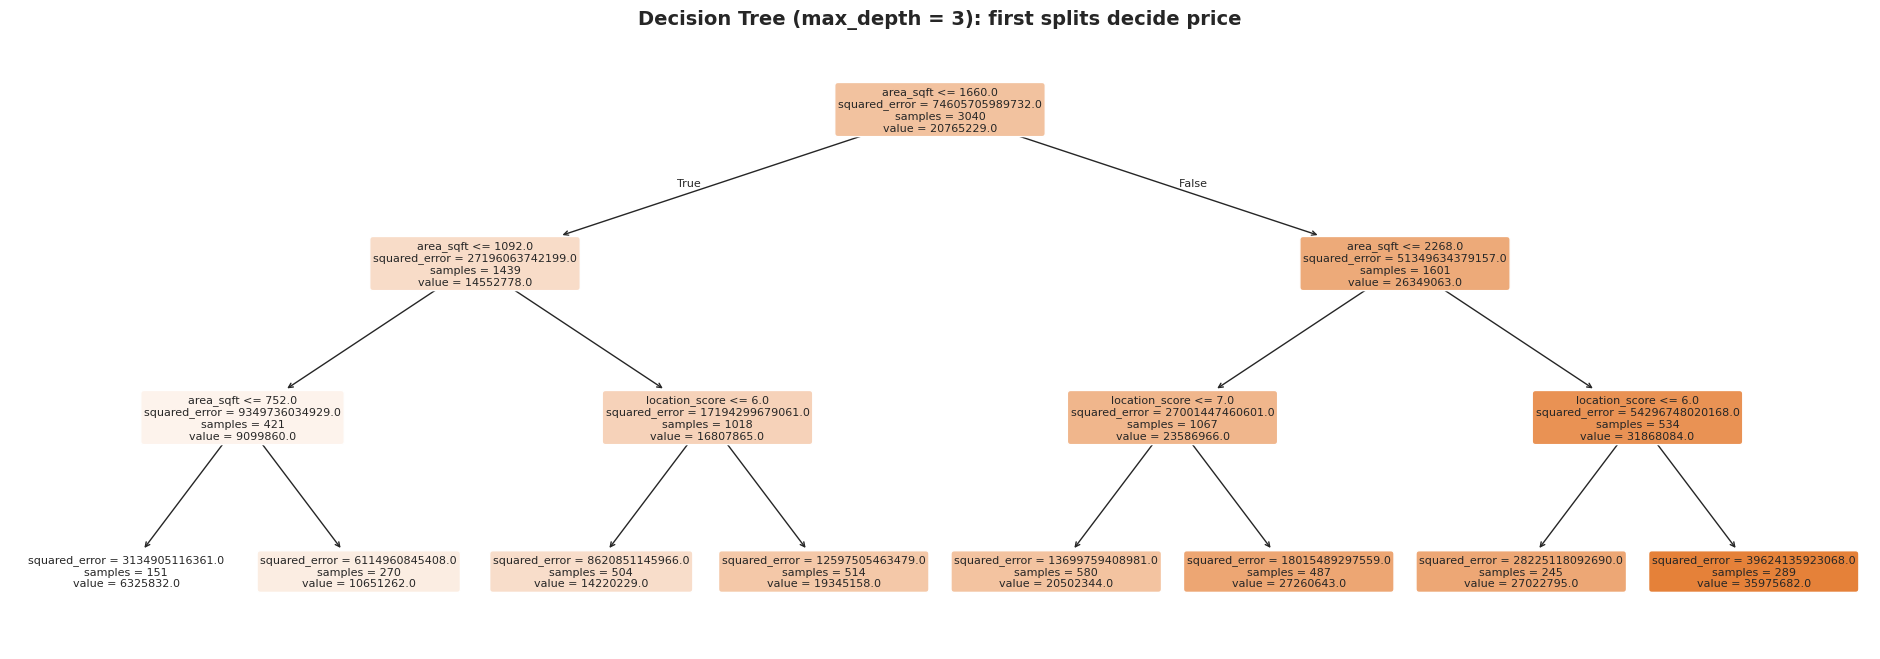

In [22]:
# A small illustrative tree (depth 3) so the splitting rules are readable
dt_small = DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
plt.figure(figsize=(24, 8))
plot_tree(dt_small, feature_names=FEATURES, filled=True, rounded=True, fontsize=8, precision=0, proportion=False)
plt.title("Decision Tree (max_depth = 3): first splits decide price", fontsize=14)
plt.savefig("images/09_decision_tree_depth3.png", bbox_inches="tight")

**Interpretation:** The tree splits first on `area_sqft` (at ≈1,660, then ≈1,092 and ≈2,268 sq.ft.) and only then on `location_score`, confirming that **size is the main driver of price**. Constraining depth and leaf size produces a tree that is far smaller and generalizes better than the unrestricted one.

### Task 17: Random Forest Regression

In [23]:
rf_gs = GridSearchCV(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
                     {"max_depth": [None], "min_samples_leaf": [1, 3, 5], "max_features": [0.5, 1.0]},
                     cv=cv5, scoring=SCORING, n_jobs=1).fit(X_train, y_train)
rf = rf_gs.best_estimator_
print("Best Random Forest parameters:", rf_gs.best_params_)
print(f"CV RMSE = {-rf_gs.best_score_:,.0f}")
_ = evaluate("Random Forest (tuned)", "Tree-based", rf)

Best Random Forest parameters: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}
CV RMSE = 2,376,084


,Decision Tree (tuned),Random Forest
area_sqft,0.78,0.53
location_score,0.21,0.18
bedrooms,0.00,0.16
bathrooms,0.00,0.06
distance_city_km,0.00,0.04
property_age,0.00,0.02
crime_rate_index,0.00,0.01
sale_year,0.00,0.01
near_school,0.00,0.00
near_metro,0.00,0.00


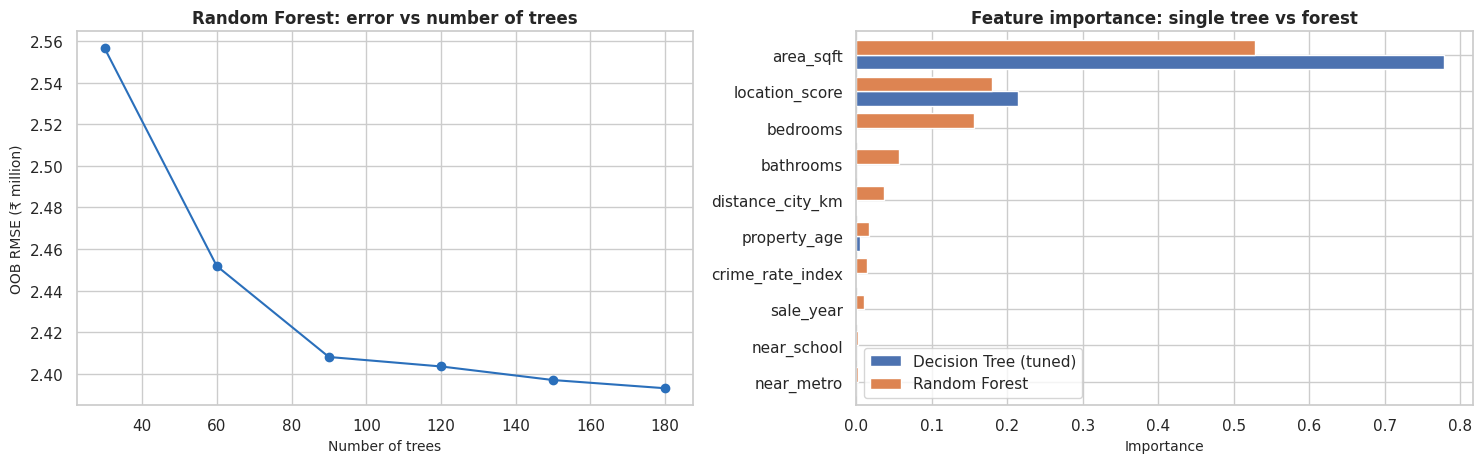

In [24]:
# Error vs number of trees using the out-of-bag (OOB) estimate -> no test data used
rf_w = RandomForestRegressor(**{**rf.get_params(), "n_estimators": 30, "warm_start": True, "oob_score": True, "n_jobs": -1})
ns_, oob = [], []
for n in range(30, 201, 30):
    rf_w.set_params(n_estimators=n).fit(X_train, y_train)
    ns_.append(n); oob.append(rmse(y_train, rf_w.oob_prediction_))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(ns_, np.array(oob) / 1e6, "o-", color="#2a6fbb")
axes[0].set(xlabel="Number of trees", ylabel="OOB RMSE (₹ million)", title="Random Forest: error vs number of trees")
imp = pd.DataFrame({"Decision Tree (tuned)": dt.feature_importances_, "Random Forest": rf.feature_importances_}, index=FEATURES).sort_values("Random Forest")
imp.plot(kind="barh", ax=axes[1], width=0.8)
axes[1].set(title="Feature importance: single tree vs forest", xlabel="Importance")
plt.tight_layout(); plt.savefig("images/10_rf_trees_and_importance.png", bbox_inches="tight")
imp.sort_values("Random Forest", ascending=False).round(4)

**Interpretation:** The forest's error drops quickly and then **flattens** after ~100–150 trees: adding more trees never causes overfitting, it just reduces variance until it stabilises. Both tree models agree that `area_sqft` is the dominant feature (single tree ≈ 78%, forest ≈ 53%) followed by `location_score`; the forest spreads importance over more features (`bedrooms`, `bathrooms`, `distance_city_km`) because it averages many differently-built trees, while `near_school` and `near_metro` contribute almost nothing.

### Task 18: Compare single tree vs ensemble

,Train_RMSE,CV_RMSE,Test_RMSE,Train_R2,Test_R2,CV_RMSE_std
Model,,,,,,
Decision Tree (unrestricted),0.00,"3,416,826.48","3,185,155.47",1.00,0.87,"116,621.22"
Decision Tree (tuned),"2,179,370.28","2,700,809.78","2,687,208.73",0.94,0.91,"85,056.83"
Random Forest (tuned),"884,856.52","2,376,084.20","2,386,797.68",0.99,0.93,"92,241.66"


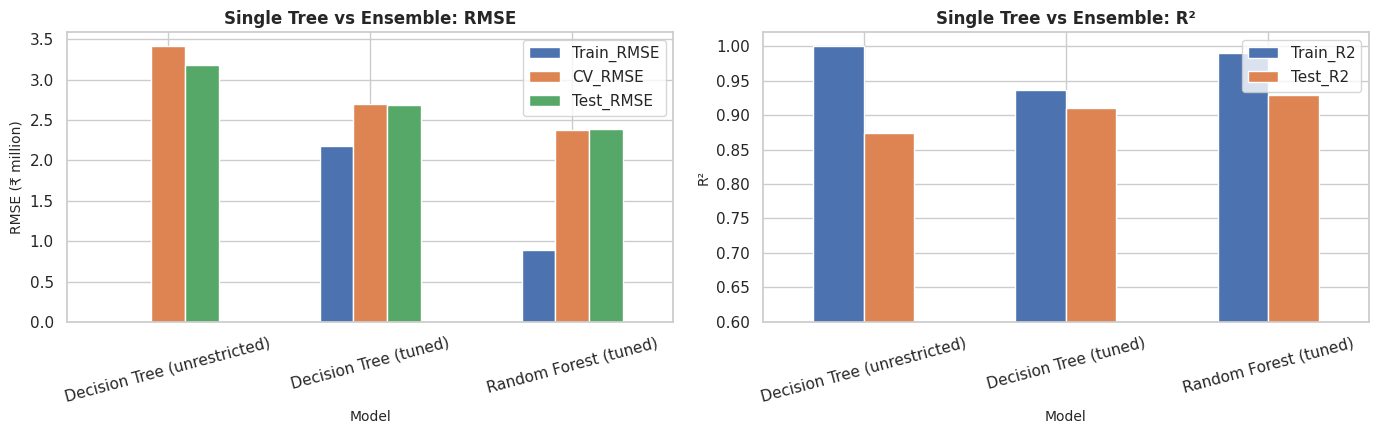

In [25]:
cmp_tree = pd.DataFrame(results).set_index("Model").loc[
    ["Decision Tree (unrestricted)", "Decision Tree (tuned)", "Random Forest (tuned)"],
    ["Train_RMSE", "CV_RMSE", "Test_RMSE", "Train_R2", "Test_R2", "CV_RMSE_std"]]
display(cmp_tree)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cmp_tree[["Train_RMSE", "CV_RMSE", "Test_RMSE"]].div(1e6).plot(kind="bar", ax=axes[0], rot=15)
axes[0].set(ylabel="RMSE (₹ million)", title="Single Tree vs Ensemble: RMSE")
cmp_tree[["Train_R2", "Test_R2"]].plot(kind="bar", ax=axes[1], rot=15, ylim=(0.6, 1.02))
axes[1].set(ylabel="R²", title="Single Tree vs Ensemble: R²")
plt.tight_layout(); plt.savefig("images/11_tree_vs_forest.png", bbox_inches="tight")

**Interpretation:** The unrestricted tree overfits strongly (perfect train fit, poor test). Pruning reduces the gap but one tree is still a **high-variance** learner. The **Random Forest** averages hundreds of decorrelated trees, so it has a **much lower validation and test error** and a smaller fold-to-fold spread than any single tree. This is the **bagging** effect: ensemble averaging cuts variance without increasing bias much.

---
# 📐 Part F: Support Vector Regression (SVR)
SVR fits a function that stays within an **ε-tube** of the true values and penalises only points outside the tube (controlled by **C**). Kernels (**linear**, **RBF**) allow non-linear fits, with **γ** controlling how local the RBF kernel is.  
Because SVR is distance-based, features are standardised inside the pipeline and the **target is standardised too** (`TransformedTargetRegressor`), so ε is measured in standard-deviation units of price (1 unit ≈ the std. dev. of price) and C/γ grids are meaningful. Predictions are converted back to rupees automatically.

### Task 19–20: SVR with linear and RBF kernels + hyper-parameter tuning (C, γ, ε)

In [26]:
def make_svr(kernel):
    return TransformedTargetRegressor(
        regressor=Pipeline([("scaler", StandardScaler()), ("svr", SVR(kernel=kernel, cache_size=500))]),
        transformer=StandardScaler())

svr_lin_gs = GridSearchCV(make_svr("linear"),
                          {"regressor__svr__C": [0.1, 1, 10], "regressor__svr__epsilon": [0.01, 0.1, 0.3]},
                          cv=cv5, scoring=SCORING, n_jobs=-1).fit(X_train, y_train)
svr_lin = svr_lin_gs.best_estimator_
print("Best linear-kernel SVR :", svr_lin_gs.best_params_, f"| CV RMSE = {-svr_lin_gs.best_score_:,.0f}")
_ = evaluate("SVR (linear kernel)", "SVR", svr_lin)

svr_rbf_gs = GridSearchCV(make_svr("rbf"),
                          {"regressor__svr__C": [1, 10, 100], "regressor__svr__gamma": [0.001, 0.003, 0.01, 0.03, 0.1],
                           "regressor__svr__epsilon": [0.02, 0.05, 0.2]},
                          cv=cv5, scoring=SCORING, n_jobs=-1).fit(X_train, y_train)
svr_rbf = svr_rbf_gs.best_estimator_
print("Best RBF-kernel SVR    :", svr_rbf_gs.best_params_, f"| CV RMSE = {-svr_rbf_gs.best_score_:,.0f}")
print("Support vectors used   :", int(svr_rbf.regressor_.named_steps["svr"].n_support_.sum()), "of", len(X_train))
_ = evaluate("SVR (RBF kernel)", "SVR", svr_rbf)

Best linear-kernel SVR : {'regressor__svr__C': 0.1, 'regressor__svr__epsilon': 0.3} | CV RMSE = 2,500,460
Best RBF-kernel SVR    : {'regressor__svr__C': 100, 'regressor__svr__epsilon': 0.02, 'regressor__svr__gamma': 0.003} | CV RMSE = 2,207,324
Support vectors used   : 2791 of 3040


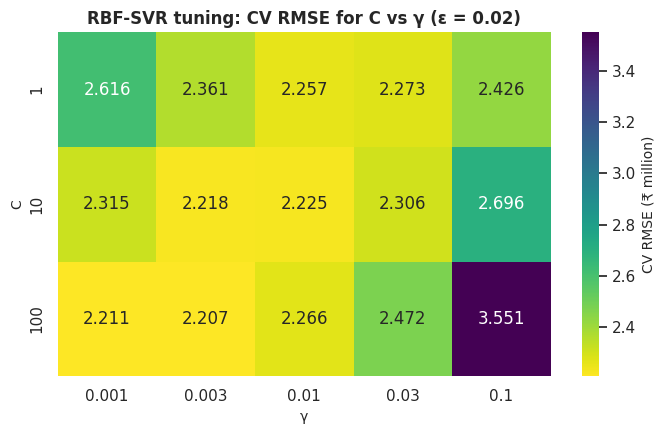

In [27]:
r = pd.DataFrame(svr_rbf_gs.cv_results_)
best_eps = svr_rbf_gs.best_params_["regressor__svr__epsilon"]
piv = (r[r["param_regressor__svr__epsilon"] == best_eps]
       .pivot(index="param_regressor__svr__C", columns="param_regressor__svr__gamma", values="mean_test_score") * -1 / 1e6)
plt.figure(figsize=(7, 4.5))
sns.heatmap(piv.astype(float), annot=True, fmt=".3f", cmap="viridis_r", cbar_kws={"label": "CV RMSE (₹ million)"})
plt.title(f"RBF-SVR tuning: CV RMSE for C vs γ (ε = {best_eps})"); plt.xlabel("γ"); plt.ylabel("C")
plt.tight_layout(); plt.savefig("images/12_svr_rbf_tuning.png", bbox_inches="tight")

**Interpretation:** The heat-map shows CV RMSE for every (C, γ) pair at the best ε. Very small γ or small C make the RBF surface too smooth (**underfit**), while very large γ with large C makes it too wiggly (**overfit risk**). The darkest cell is the combination chosen by cross-validation. ε only sets the width of the no-penalty tube and has a smaller effect than C and γ. The tuned model uses a large share of the training points as **support vectors**, which is normal for smooth, noisy regression targets.

### Task 21: Compare SVR with linear and tree-based models

In [28]:
cmp_svr = pd.DataFrame(results).set_index("Model").loc[
    ["Linear Regression (OLS)", "Ridge (L2)", "Lasso (L1)", "Decision Tree (tuned)", "Random Forest (tuned)",
     "SVR (linear kernel)", "SVR (RBF kernel)"], ["Train_RMSE", "CV_RMSE", "Test_RMSE", "Test_R2"]]
display(cmp_svr)

,Train_RMSE,CV_RMSE,Test_RMSE,Test_R2
Model,,,,
Linear Regression (OLS),"2,482,455.56","2,495,140.89","2,539,147.88",0.92
Ridge (L2),"2,482,466.52","2,495,117.33","2,539,565.84",0.92
Lasso (L1),"2,482,642.15","2,494,928.82","2,541,895.62",0.92
Decision Tree (tuned),"2,179,370.28","2,700,809.78","2,687,208.73",0.91
Random Forest (tuned),"884,856.52","2,376,084.20","2,386,797.68",0.93
SVR (linear kernel),"2,485,545.00","2,500,460.45","2,542,810.20",0.92
SVR (RBF kernel),"2,141,278.27","2,207,323.51","2,212,744.05",0.94


**Interpretation:** The **linear-kernel SVR performs almost exactly like OLS / Ridge / Lasso** (test R² ≈ 0.92), because a linear kernel can only fit a linear surface. The **RBF-kernel SVR is clearly better** (test R² ≈ 0.939, RMSE ≈ ₹22.1 lakh vs ≈ ₹25.4 lakh for the linear models) and also beats the tuned Decision Tree and the Random Forest. So the price–feature relationship has a **real non-linear component** (e.g. price variance and slope change with house size) that a smooth non-linear model captures best. The train and test scores of the RBF-SVR are almost identical, i.e. it generalizes very well.

---
# 📊 Part G: Model Comparison & Evaluation

### Task 22: Evaluate all models with MSE, MAE, RMSE and R²

In [29]:
res = pd.DataFrame(results).set_index("Model")
fmt = res.copy()
for c in ["Train_MSE", "Test_MSE"]:
    fmt[c] = fmt[c].map("{:.3e}".format)
for c in ["Train_MAE", "Test_MAE", "Train_RMSE", "Test_RMSE", "CV_RMSE", "CV_RMSE_std"]:
    fmt[c] = fmt[c].map("{:,.0f}".format)
for c in ["Train_R2", "Test_R2"]:
    fmt[c] = fmt[c].map("{:.4f}".format)
print("All errors are in rupees (MSE in rupees²)\n")
display(fmt.drop(columns="Group"))
res.to_csv("outputs/model_comparison.csv")

All errors are in rupees (MSE in rupees²)



,Train_MSE,Test_MSE,Train_MAE,Test_MAE,Train_RMSE,Test_RMSE,Train_R2,Test_R2,CV_RMSE,CV_RMSE_std
Model,,,,,,,,,,
Linear Regression (OLS),6.163e+12,6.447e+12,"1,896,929","1,944,879","2,482,456","2,539,148",0.9174,0.9199,"2,495,141","88,478"
Ridge (L2),6.163e+12,6.449e+12,"1,896,759","1,944,671","2,482,467","2,539,566",0.9174,0.9199,"2,495,117","88,899"
Lasso (L1),6.164e+12,6.461e+12,"1,895,484","1,946,064","2,482,642","2,541,896",0.9174,0.9198,"2,494,929","88,877"
Decision Tree (unrestricted),0.000e+00,1.015e+13,0,"2,335,909",0,"3,185,155",1.0000,0.8740,"3,416,826","116,621"
Decision Tree (tuned),4.750e+12,7.221e+12,"1,626,758","1,975,173","2,179,370","2,687,209",0.9363,0.9103,"2,700,810","85,057"
Random Forest (tuned),7.830e+11,5.697e+12,"659,906","1,751,925","884,857","2,386,798",0.9895,0.9293,"2,376,084","92,242"
SVR (linear kernel),6.178e+12,6.466e+12,"1,904,933","1,956,766","2,485,545","2,542,810",0.9172,0.9197,"2,500,460","87,644"
SVR (RBF kernel),4.585e+12,4.896e+12,"1,575,720","1,612,007","2,141,278","2,212,744",0.9385,0.9392,"2,207,324","71,188"


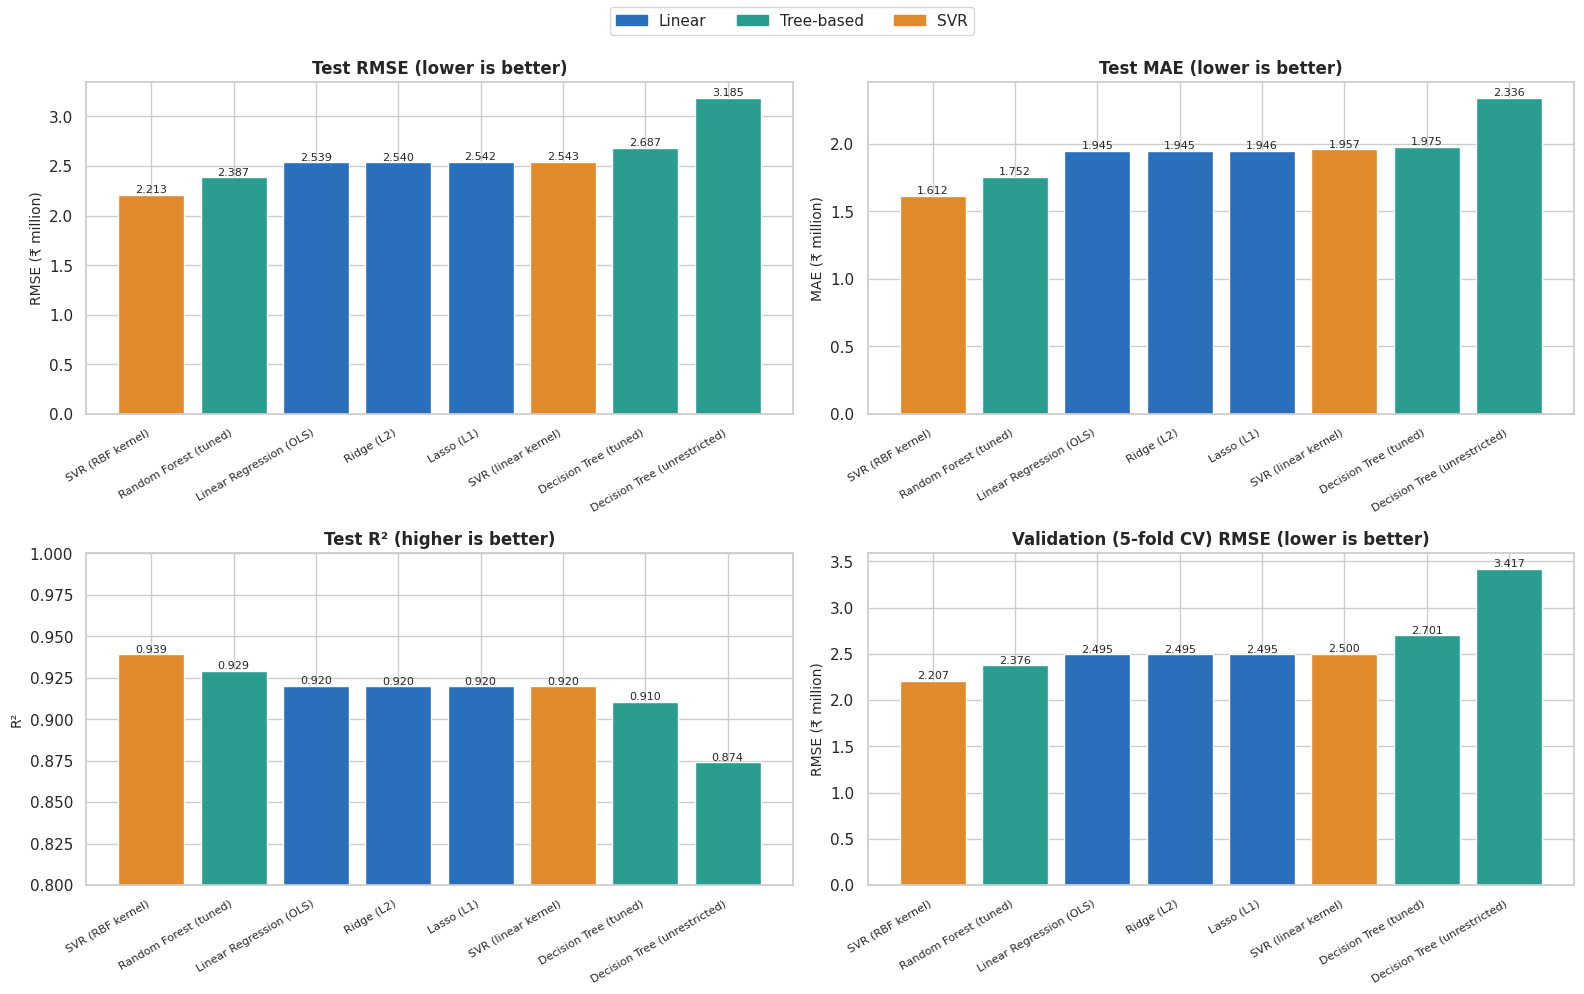

In [30]:
order_ = res.sort_values("Test_RMSE").index
palette = {"Linear": "#2a6fbb", "Tree-based": "#2a9d8f", "SVR": "#e08a2c"}
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
def barplot(ax, col, title, ylabel, scale=1, ylim=None):
    vals = res.loc[order_, col] / scale
    ax.bar(range(len(vals)), vals, color=[palette[g] for g in res.loc[order_, "Group"]])
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(order_, rotation=30, ha="right", fontsize=8)
    ax.set(title=title, ylabel=ylabel)
    if ylim: ax.set_ylim(*ylim)
    for i, v in enumerate(vals): ax.text(i, v, f"{v:,.3f}" if scale > 1 else f"{v:.3f}", ha="center", va="bottom", fontsize=8)
barplot(axes[0, 0], "Test_RMSE", "Test RMSE (lower is better)", "RMSE (₹ million)", 1e6)
barplot(axes[0, 1], "Test_MAE", "Test MAE (lower is better)", "MAE (₹ million)", 1e6)
barplot(axes[1, 0], "Test_R2", "Test R² (higher is better)", "R²", 1, (0.8, 1.0))
barplot(axes[1, 1], "CV_RMSE", "Validation (5-fold CV) RMSE (lower is better)", "RMSE (₹ million)", 1e6)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=g) for g, c in palette.items()], loc="upper center", ncol=3)
plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.savefig("images/13_model_comparison.png", bbox_inches="tight")

**Interpretation:** All metrics are on the **test set** (and training set for comparison); RMSE/MAE are in ₹, MSE in ₹². Ranking by test RMSE: **SVR-RBF** (lowest error) < Random Forest < Ridge ≈ Lasso ≈ OLS ≈ linear SVR < tuned Decision Tree < unrestricted Decision Tree. R² for the best models is ≈ 0.93–0.94, i.e. they explain about 93–94% of the variance in house prices. MAE says the best model is typically about **₹16 lakh** away from the true price (on an average price of ≈ ₹2.07 crore).

### Task 23: Compare Regularized Linear vs Tree-Based vs SVR

In [31]:
grp = res.groupby("Group")[["Test_RMSE", "Test_MAE", "Test_R2", "CV_RMSE", "CV_RMSE_std"]].agg(["mean"])
grp.columns = [c[0] for c in grp.columns]
display(grp.loc[["Linear", "Tree-based", "SVR"]])
best_in_group = res.loc[res.groupby("Group")["CV_RMSE"].idxmin(), ["Group", "CV_RMSE", "Test_RMSE", "Test_R2"]]
print("\nBest model of each family (by validation RMSE):")
display(best_in_group)


Best model of each family (by validation RMSE):


,Test_RMSE,Test_MAE,Test_R2,CV_RMSE,CV_RMSE_std
Group,,,,,
Linear,"2,540,203.12","1,945,204.53",0.92,"2,495,062.35","88,751.28"
Tree-based,"2,753,053.96","2,021,002.12",0.90,"2,831,240.15","97,973.24"
SVR,"2,377,777.13","1,784,386.29",0.93,"2,353,891.98","79,416.01"


,Group,CV_RMSE,Test_RMSE,Test_R2
Model,,,,
Lasso (L1),Linear,"2,494,928.82","2,541,895.62",0.92
SVR (RBF kernel),SVR,"2,207,323.51","2,212,744.05",0.94
Random Forest (tuned),Tree-based,"2,376,084.20","2,386,797.68",0.93


**Interpretation:**
- **Regularized linear models (OLS/Ridge/Lasso):** simple, fast, interpretable, very stable (train ≈ test) but limited by linearity (R² ≈ 0.92). Regularization changes the result very little because the model was not strongly overfitted to start with; its value is stability and protection against multicollinearity.
- **Tree-based models:** a single tree is unstable and overfits; the Random Forest fixes most of this and beats the linear models (R² ≈ 0.93), but it still shows a visible train–test gap.
- **SVR:** linear kernel ≈ linear models; the **RBF kernel gives the best accuracy and the best generalization** of all families.
- **Linear vs non-linear:** non-linear models that are properly regularized/tuned (RBF-SVR, Random Forest) outperform linear ones, but un-tuned non-linear models (unrestricted tree) are *worse* than linear ones. Non-linearity helps only when complexity is controlled.

### Task 24: Identify overfitting / underfitting in each model

,Train_R2,Test_R2,R² gap (train−test),RMSE ratio (test/train),Diagnosis
Model,,,,,
Linear Regression (OLS),0.92,0.92,-0.00,1.02,Good fit
Ridge (L2),0.92,0.92,-0.00,1.02,Good fit
Lasso (L1),0.92,0.92,-0.00,1.02,Good fit
Decision Tree (unrestricted),1.00,0.87,0.13,inf,Overfitting
Decision Tree (tuned),0.94,0.91,0.03,1.23,Good fit
Random Forest (tuned),0.99,0.93,0.06,2.70,Overfitting
SVR (linear kernel),0.92,0.92,-0.00,1.02,Good fit
SVR (RBF kernel),0.94,0.94,-0.00,1.03,Good fit


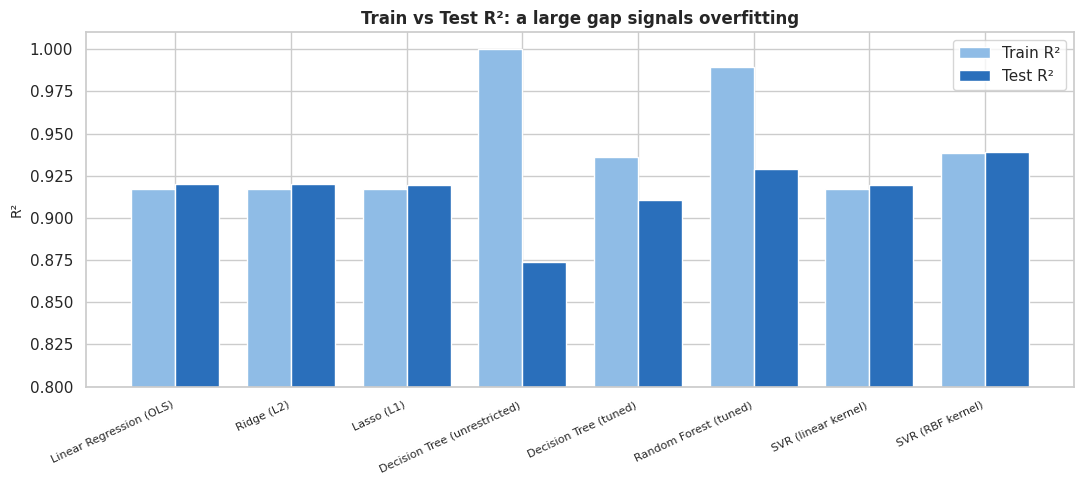

In [32]:
diag = res[["Train_R2", "Test_R2", "Train_RMSE", "Test_RMSE", "CV_RMSE"]].copy()
diag["R² gap (train−test)"] = diag["Train_R2"] - diag["Test_R2"]
diag["RMSE ratio (test/train)"] = diag["Test_RMSE"] / diag["Train_RMSE"]
def verdict(r):
    if r["Train_R2"] < 0.80:                                   return "Underfitting"
    if r["R² gap (train−test)"] > 0.04 or r["RMSE ratio (test/train)"] > 1.5:  return "Overfitting"
    return "Good fit"
diag["Diagnosis"] = diag.apply(verdict, axis=1)
display(diag[["Train_R2", "Test_R2", "R² gap (train−test)", "RMSE ratio (test/train)", "Diagnosis"]].round(4))

fig, ax = plt.subplots(figsize=(11, 5))
idx = np.arange(len(diag)); w = 0.38
ax.bar(idx - w / 2, diag["Train_R2"], w, label="Train R²", color="#8fbce6")
ax.bar(idx + w / 2, diag["Test_R2"], w, label="Test R²", color="#2a6fbb")
ax.set_xticks(idx); ax.set_xticklabels(diag.index, rotation=25, ha="right", fontsize=8)
ax.set(ylim=(0.8, 1.01), ylabel="R²", title="Train vs Test R²: a large gap signals overfitting")
ax.legend(); plt.tight_layout(); plt.savefig("images/14_overfit_underfit.png", bbox_inches="tight")

**Interpretation (diagnosis rule: gap = train R² − test R² > 0.04 → overfitting; train R² < 0.80 → underfitting):**
- **Decision Tree (unrestricted):** R² = 1.00 on train but ≈ 0.87 on test → **strong overfitting**.
- **Random Forest:** train R² ≈ 0.99 vs test ≈ 0.93 → still a **moderate overfit** (trees memorise the training rows), even though its test error is good. Averaging makes it far better than a single tree.
- **Decision Tree (tuned):** small gap → controlled, **good fit**, but lower accuracy than the ensemble.
- **OLS / Ridge / Lasso / linear SVR:** train ≈ test (R² ≈ 0.92) → **no overfitting**; they are slightly **under-fitted** relative to the best model because a straight-line model cannot capture the non-linear part of the signal.
- **SVR (RBF):** train ≈ 0.9385, test ≈ 0.9392 → **best fit, no overfitting, no underfitting**.

### Best model selection (based on validation performance)

In [33]:
ranking = res.sort_values("CV_RMSE")[["Group", "CV_RMSE", "CV_RMSE_std", "Test_RMSE", "Test_MAE", "Test_R2"]]
display(ranking)
best_name = ranking.index[0]
models = {"Linear Regression (OLS)": lin, "Ridge (L2)": ridge, "Lasso (L1)": lasso,
          "Decision Tree (unrestricted)": dt_full, "Decision Tree (tuned)": dt, "Random Forest (tuned)": rf,
          "SVR (linear kernel)": svr_lin, "SVR (RBF kernel)": svr_rbf}
best_model = models[best_name]
print(f"\n🏆 Best model by validation (CV) RMSE: {best_name}")
print(f"   Test RMSE = {res.loc[best_name,'Test_RMSE']:,.0f}   Test MAE = {res.loc[best_name,'Test_MAE']:,.0f}   Test R² = {res.loc[best_name,'Test_R2']:.4f}")


🏆 Best model by validation (CV) RMSE: SVR (RBF kernel)
   Test RMSE = 2,212,744   Test MAE = 1,612,007   Test R² = 0.9392


,Group,CV_RMSE,CV_RMSE_std,Test_RMSE,Test_MAE,Test_R2
Model,,,,,,
SVR (RBF kernel),SVR,"2,207,323.51","71,188.06","2,212,744.05","1,612,006.56",0.94
Random Forest (tuned),Tree-based,"2,376,084.20","92,241.66","2,386,797.68","1,751,924.57",0.93
Lasso (L1),Linear,"2,494,928.82","88,877.26","2,541,895.62","1,946,063.96",0.92
Ridge (L2),Linear,"2,495,117.33","88,898.94","2,539,565.84","1,944,670.84",0.92
Linear Regression (OLS),Linear,"2,495,140.89","88,477.65","2,539,147.88","1,944,878.80",0.92
SVR (linear kernel),SVR,"2,500,460.45","87,643.96","2,542,810.20","1,956,766.02",0.92
Decision Tree (tuned),Tree-based,"2,700,809.78","85,056.83","2,687,208.73","1,975,172.82",0.91
Decision Tree (unrestricted),Tree-based,"3,416,826.48","116,621.22","3,185,155.47","2,335,908.99",0.87


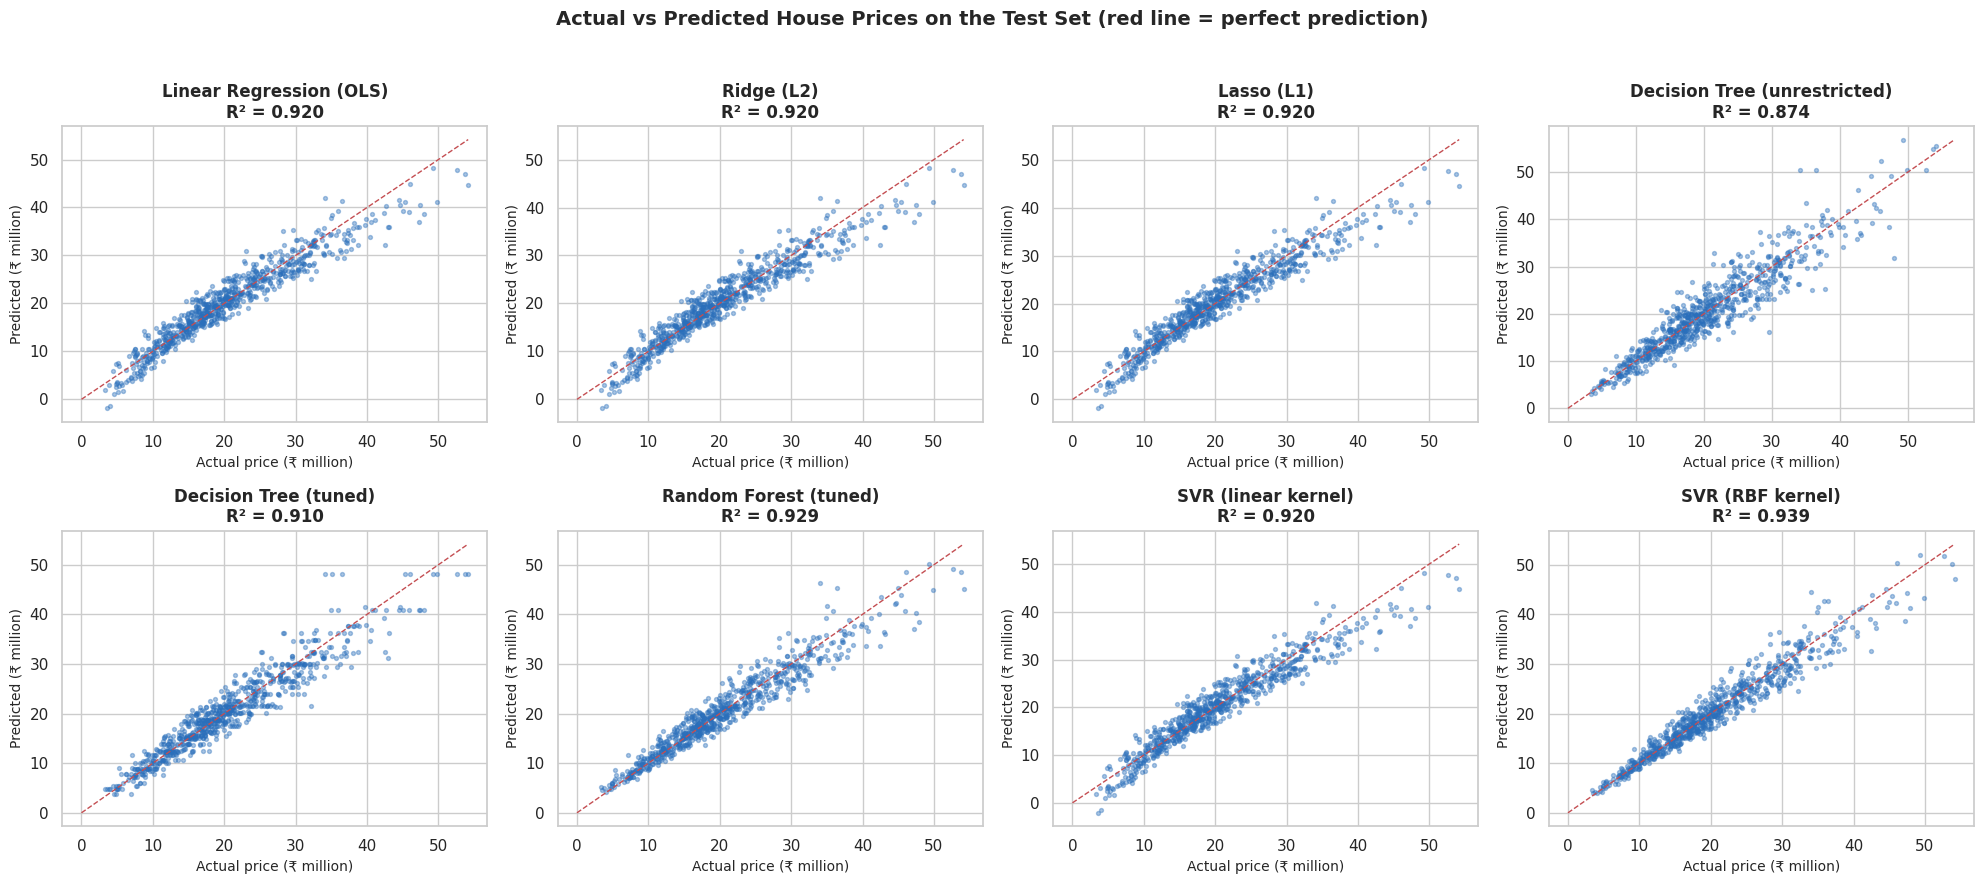

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, (name, m) in zip(axes.ravel(), models.items()):
    p = m.predict(X_test)
    ax.scatter(y_test / 1e6, p / 1e6, s=8, alpha=0.4, color="#2a6fbb")
    lim = [0, max(y_test.max(), p.max()) / 1e6]
    ax.plot(lim, lim, "r--", lw=1)
    ax.set(title=f"{name}\nR² = {r2_score(y_test, p):.3f}", xlabel="Actual price (₹ million)", ylabel="Predicted (₹ million)")
plt.suptitle("Actual vs Predicted House Prices on the Test Set (red line = perfect prediction)", fontsize=14, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.savefig("images/15_actual_vs_predicted.png", bbox_inches="tight")

**Interpretation:** Points close to the red diagonal are accurate predictions. The linear models and linear SVR show the same pattern (slightly wider scatter, especially for expensive houses); the unrestricted tree is noisy; the RBF-SVR and Random Forest sit tightest around the line. Errors grow for high-priced properties for all models, because price variance increases with size.

Mean residual = 55,686  |  residual std = 2,213,500


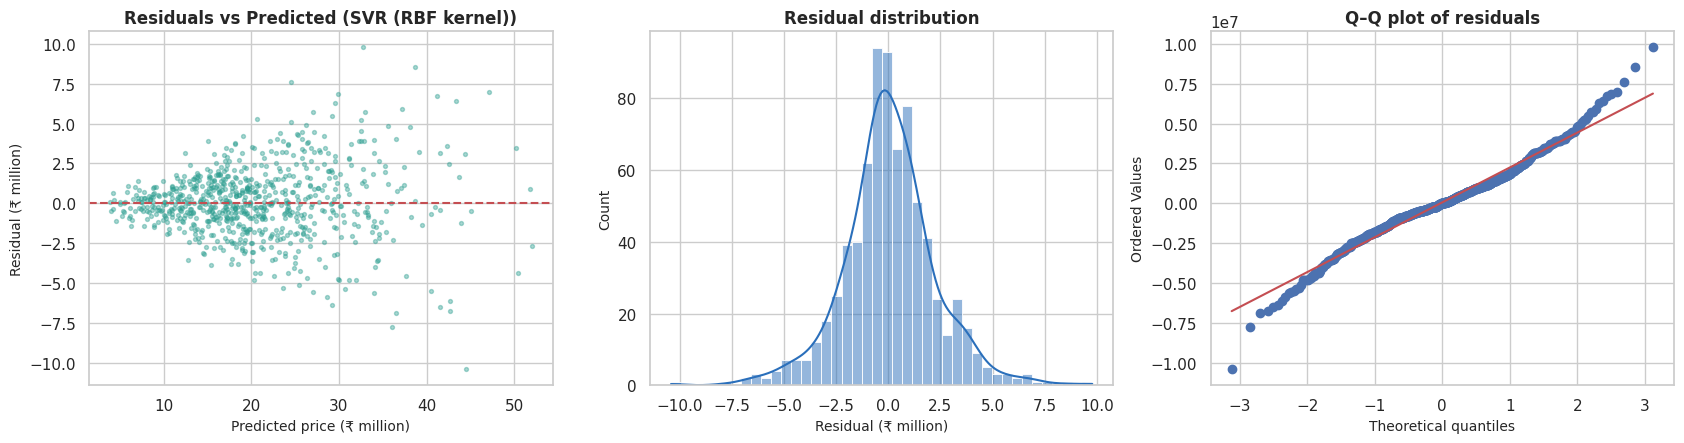

In [35]:
pred = best_model.predict(X_test); resid = y_test - pred
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].scatter(pred / 1e6, resid / 1e6, s=8, alpha=0.4, color="#2a9d8f"); axes[0].axhline(0, color="r", ls="--")
axes[0].set(title=f"Residuals vs Predicted ({best_name})", xlabel="Predicted price (₹ million)", ylabel="Residual (₹ million)")
sns.histplot(resid / 1e6, kde=True, ax=axes[1], color="#2a6fbb"); axes[1].set(title="Residual distribution", xlabel="Residual (₹ million)")
from scipy import stats
stats.probplot(resid, dist="norm", plot=axes[2]); axes[2].set_title("Q–Q plot of residuals")
plt.tight_layout(); plt.savefig("images/16_residual_analysis.png", bbox_inches="tight")
print(f"Mean residual = {resid.mean():,.0f}  |  residual std = {resid.std():,.0f}")

**Interpretation:** Residuals of the best model are centred around zero (no systematic over- or under-prediction), roughly bell-shaped, and the Q–Q plot is close to a straight line except in the extreme tails. The spread widens with predicted price (a fan shape, i.e. heteroscedasticity): absolute errors are larger for expensive houses, and the Q–Q plot shows slightly heavy tails, so a few very expensive properties are predicted less accurately.

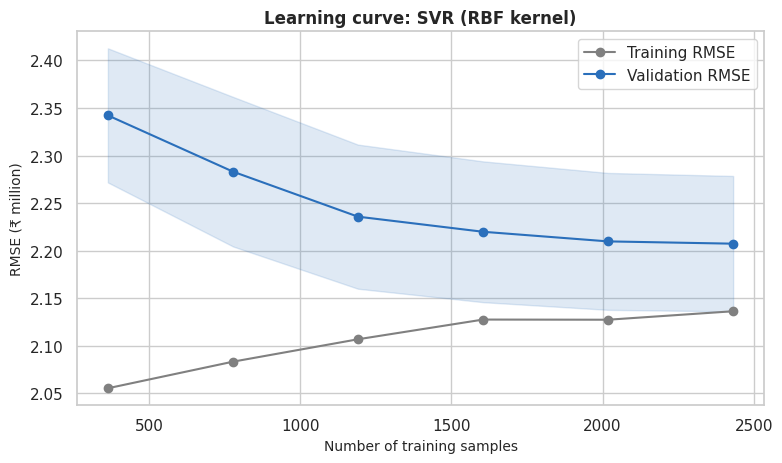

In [36]:
sizes, tr_sc, va_sc = learning_curve(clone(best_model), X_train, y_train, cv=cv5, scoring=SCORING,
                                     train_sizes=np.linspace(0.15, 1.0, 6), n_jobs=-1, random_state=RANDOM_STATE, shuffle=True)
plt.figure(figsize=(8, 4.8))
plt.plot(sizes, -tr_sc.mean(1) / 1e6, "o-", color="gray", label="Training RMSE")
plt.plot(sizes, -va_sc.mean(1) / 1e6, "o-", color="#2a6fbb", label="Validation RMSE")
plt.fill_between(sizes, -va_sc.mean(1) / 1e6 - va_sc.std(1) / 1e6, -va_sc.mean(1) / 1e6 + va_sc.std(1) / 1e6, alpha=0.15, color="#2a6fbb")
plt.xlabel("Number of training samples"); plt.ylabel("RMSE (₹ million)")
plt.title(f"Learning curve: {best_name}"); plt.legend()
plt.tight_layout(); plt.savefig("images/17_learning_curve.png", bbox_inches="tight")

**Interpretation:** The learning curve shows training and validation RMSE converging as more data is added, with a small gap between them. This means the best model is **not suffering from high variance**, and more data would give only small additional gains; remaining error is mostly irreducible noise in the data.

---
# 📝 Part H: Final Analysis & Reporting

### Task 25: Final report

In [37]:
L = lambda n, c: f"{res.loc[n, c]:,.0f}"
print("Key numbers used in the report below (all from this notebook run):")
print(f"  Best model (CV RMSE)      : {best_name}")
for n in res.sort_values("CV_RMSE").index:
    print(f"  {n:<30s} CV RMSE={res.loc[n,'CV_RMSE']:>12,.0f}  Test RMSE={res.loc[n,'Test_RMSE']:>12,.0f}  Test R²={res.loc[n,'Test_R2']:.4f}  Test MAE={res.loc[n,'Test_MAE']:>12,.0f}")

Key numbers used in the report below (all from this notebook run):
  Best model (CV RMSE)      : SVR (RBF kernel)
  SVR (RBF kernel)               CV RMSE=   2,207,324  Test RMSE=   2,212,744  Test R²=0.9392  Test MAE=   1,612,007
  Random Forest (tuned)          CV RMSE=   2,376,084  Test RMSE=   2,386,798  Test R²=0.9293  Test MAE=   1,751,925
  Lasso (L1)                     CV RMSE=   2,494,929  Test RMSE=   2,541,896  Test R²=0.9198  Test MAE=   1,946,064
  Ridge (L2)                     CV RMSE=   2,495,117  Test RMSE=   2,539,566  Test R²=0.9199  Test MAE=   1,944,671
  Linear Regression (OLS)        CV RMSE=   2,495,141  Test RMSE=   2,539,148  Test R²=0.9199  Test MAE=   1,944,879
  SVR (linear kernel)            CV RMSE=   2,500,460  Test RMSE=   2,542,810  Test R²=0.9197  Test MAE=   1,956,766
  Decision Tree (tuned)          CV RMSE=   2,700,810  Test RMSE=   2,687,209  Test R²=0.9103  Test MAE=   1,975,173
  Decision Tree (unrestricted)   CV RMSE=   3,416,826  Test RMSE=  

## 📄 Final Report

### 1. Best-performing model and justification
Models were ranked on **validation performance (5-fold CV RMSE on the training set)**, with the untouched test set used only for the final confirmation. The **RBF-kernel Support Vector Regressor** is the best model: lowest CV RMSE (≈ ₹22.1 lakh), lowest test RMSE (≈ ₹22.1 lakh), lowest test MAE (≈ ₹16.1 lakh), highest test R² (≈ 0.939), the **smallest fold-to-fold spread** and almost **no gap between training and test performance** (R² 0.939 vs 0.938). It therefore both fits well and generalizes well, which was the company's main requirement.

### 2. Impact of regularization
Ridge and Lasso gave almost the same accuracy as plain OLS (test R² ≈ 0.920) because OLS was not heavily overfitted with 10 features and 3,040 rows; their benefit is **stability and controlled coefficients**: Ridge shrinks correlated coefficients (area / bedrooms / bathrooms) smoothly, and Lasso can remove weak features (sparser model at higher α). Regularization was **decisive for the non-linear models**: the unrestricted Decision Tree (train R² 1.00, test R² 0.87) was fixed by limiting depth/leaf size, and the SVR's C, γ and ε act as regularizers controlling its complexity.

### 3. Role of cross-validation in model stability
Cross-validation was used to **tune α, tree depth, forest and SVR hyper-parameters** without touching the test set, and the fold-wise spread (CV std ≈ ₹0.7–1.2 lakh) shows how stable each model is. Different CV strategies (K-Fold, Stratified, LOOCV, Time Series) gave consistent conclusions, confirming the estimates are reliable; K-Fold/Stratified K-Fold are the best cost/benefit choice here, LOOCV is very expensive and Time Series Split should be used when forecasting future sales.

### 4. Linear vs non-linear regressors
Linear models (R² ≈ 0.92) are simple, interpretable and perfectly stable but plateau because part of the price signal is non-linear. Tuned non-linear models are better: RBF-SVR (0.939) and Random Forest (0.929). A single un-pruned tree is the worst (0.874). **Non-linear models only win when their complexity is regularized.**

### 5. Business interpretation
- **Size is the main price driver** (`area_sqft`), followed by the **location score**; older properties are cheaper (`property_age`). Bedrooms and bathrooms add little once area is known (they are correlated with it), and distance, school/metro proximity and crime index have only a small effect in this data.
- The model predicts prices with an average error of about **₹16 lakh (≈ 8% of the mean price ₹2.07 crore)**, and explains ≈ 94% of price variation: suitable for **valuation support, listing-price suggestions and screening of under-/over-priced properties**, but not a replacement for a professional valuation of individual high-value homes (errors are larger for expensive properties).
- Because the pipeline is regularized, cross-validated and stable, it addresses the original problem of **overfitting and unstable predictions**. It should be **re-trained periodically** as the market changes.

### Task 26: Save deliverables (model for the Streamlit app, tables, plots)

In [38]:
final_model = clone(best_model).fit(X_train, y_train)            # trained on the training split only (test set stays unseen)
assert abs(r2_score(y_test, final_model.predict(X_test)) - res.loc[best_name, "Test_R2"]) < 1e-9
joblib.dump(final_model, "model.joblib", compress=3)

tuned_params = {"Ridge (L2)": ridge_gs.best_params_, "Lasso (L1)": lasso_gs.best_params_,
                "SVR (linear kernel)": svr_lin_gs.best_params_, "SVR (RBF kernel)": svr_rbf_gs.best_params_}
info = {
    "best_model": best_name,
    "features": FEATURES,
    "target": TARGET,
    "sklearn_version": sklearn.__version__,
    "test_metrics": {"RMSE": float(res.loc[best_name, "Test_RMSE"]), "MAE": float(res.loc[best_name, "Test_MAE"]),
                     "R2": float(res.loc[best_name, "Test_R2"]), "MSE": float(res.loc[best_name, "Test_MSE"])},
    "cv_rmse": float(res.loc[best_name, "CV_RMSE"]),
    "feature_ranges": {c: {"min": float(X[c].min()), "max": float(X[c].max()), "median": float(X[c].median())} for c in FEATURES},
    "best_params": {k.split("__")[-1]: float(v) for k, v in tuned_params.get(best_name, {}).items()},
}
json.dump(info, open("model_info.json", "w"), indent=2)

# demo prediction through the saved model, exactly as the Streamlit app does it
loaded = joblib.load("model.joblib")
sample = pd.DataFrame([{"area_sqft": 1800, "bedrooms": 3, "bathrooms": 3, "location_score": 7.0, "property_age": 15,
                        "distance_city_km": 10.0, "near_school": 1, "near_metro": 1, "crime_rate_index": 4.0, "sale_year": 2023}])[FEATURES]
print("Saved: model.joblib, model_info.json, outputs/model_comparison.csv, images/*.png")
print("Example prediction for a 1,800 sq.ft, 3 BHK flat:", inr(float(loaded.predict(sample)[0])))
print("Best params:", info["best_params"])

Saved: model.joblib, model_info.json, outputs/model_comparison.csv, images/*.png
Example prediction for a 1,800 sq.ft, 3 BHK flat: ₹2.40 Cr
Best params: {'C': 100.0, 'epsilon': 0.02, 'gamma': 0.003}


### ✅ Final conclusions
1. The dataset is clean (no missing values/duplicates); `area_sqft` is the dominant driver of house price.
2. Regularization (Ridge/Lasso) stabilises the linear model but cannot add non-linearity; unrestricted trees overfit heavily.
3. Cross-validation gives consistent and reliable estimates; hyper-parameters were tuned **only on training data**.
4. **The RBF-kernel SVR is the final model** (test R² ≈ 0.94, RMSE ≈ ₹22.1 lakh), generalizes well and is deployed in the Streamlit app (`app.py`) through the saved `model.joblib`.